# Sistema Especialista com Aprendizado Supervisionado
## Triagem de golpes de falsa central de atendimento (banco/operadora)

**Disciplina:** Inteligência Artificial e LFA | Sistemas Especialistas

Execute este notebook no Google Colab ou no Jupyter, **de cima para baixo**. No Colab: *Arquivo > Fazer upload de notebook*.

**Tema:** filtragem de mensagens/contatos indesejados.

**Materiais-guia da disciplina:** (1) o notebook *Aprendizado de Máquina – Introdução* (fluxo de treino/teste e integração ML + regras) e (2) o texto *Sistemas Especialistas: guia completo (IA)* (componentes, aplicações, vantagens e limitações).

**Objetivo:** treinar um classificador que lê o **texto** de uma mensagem recebida e usar a sua previsão como um **fato** em um sistema especialista que diz se o contato é um golpe, **qual tipo de golpe** e **o que fazer**.

**Problema do dia a dia:** golpistas se passam por banco ou operadora (por ligação, SMS, WhatsApp ou e-mail) para roubar códigos, senhas e dinheiro. A pessoa precisa decidir rapidamente se o contato é confiável.

| Item | Definição |
|---|---|
| **Entradas** | (1) texto da mensagem recebida (opcional); (2) respostas sim/não sobre o contato (pediu código? pediu Pix? ...) |
| **Rótulo do modelo de ML** | `perfil` da mensagem: `golpe` ou `legitimo` |
| **Saída do sistema especialista** | grau de suspeita (com fator de certeza), tipo provável de golpe e plano de ação |

> **Aviso:** os dados de treino são **fictícios (simulados)**, pequenos e escritos para fins didáticos. Este exemplo **não valida** uma ferramenta de segurança real e **não substitui** o atendimento oficial do banco ou da operadora.

## Perguntas de leitura

**O que é aprendizado de máquina?**
É a área da IA em que o programa **aprende regras a partir de exemplos (dados)** em vez de receber as regras escritas à mão por um programador. Na programação tradicional: `Dados + Algoritmo = Respostas`. No aprendizado supervisionado: `Dados + Rótulos (respostas) = Modelo (regras)`.

**O que são atributos e rótulos?**
*Atributos* (`X`) são as características que descrevem cada exemplo (aqui: nº de links, nº de palavras de urgência etc.). O *rótulo* (`y`) é a resposta conhecida que queremos prever (aqui: `golpe` ou `legitimo`). O rótulo **nunca** entra em `X`, senão o modelo "cola".

**Como classificação difere de regressão?**
Na *classificação* a saída é uma **categoria** (ex.: golpe/legítimo). Na *regressão* a saída é um **número contínuo** (ex.: prejuízo estimado em reais). Este projeto usa classificação.

**Por que separar treino e teste?**
Para medir a **generalização**. Se avaliarmos o modelo nos mesmos exemplos em que ele aprendeu, ele pode apenas "decorar" (overfitting) e a acurácia fica falsamente alta. O conjunto de teste são exemplos que o modelo **nunca viu**.

## Mapa do projeto: o que é cada coisa

O sistema funciona em **duas fases** (arquitetura híbrida do tratado):

```
 texto da mensagem ──► [FASE 1: Machine Learning] ──► fato dinâmico "ml_golpe"
                                                            │
 respostas do usuário (sim/não) ───────────────────────────►│
                                                            ▼
                        [FASE 2: Sistema Especialista]  Base de Conhecimento (regras)
                                                         Memória de Trabalho (fatos)
                                                         Motor de Inferência
                                                            │
                                                            ▼
                         suspeita (%) + tipo de golpe + plano de ação + explicação
```

| Termo | O que é |
|---|---|
| **Fato** | Uma afirmação sobre o caso atual, ex.: `s_pede_codigo` (pediram um código). |
| **Regra** | Estrutura `SE premissas ENTÃO conclusão`, escrita por pessoas, ex.: `SE pediu código ENTÃO suspeita de golpe`. |
| **Base de Conhecimento (BC)** | O conjunto de perguntas e regras do especialista. É o conhecimento *estático*. |
| **Memória de Trabalho (MT)** | Onde ficam os fatos da consulta atual e as conclusões deduzidas. É *dinâmica*. |
| **Motor de Inferência (MI)** | O "cérebro": cruza fatos com regras e deduz conclusões. Não conhece o assunto, só raciocina. |
| **Encadeamento para frente** | Parte dos fatos e dispara regras até não haver novidades (*data-driven*). |
| **Encadeamento para trás** | Parte de um objetivo e só pergunta o que for necessário para prová-lo (*goal-driven*). |
| **Fator de certeza (CF)** | Número de -1 a +1: quanto uma evidência apoia (+) ou contraria (-) uma conclusão. Técnica do sistema MYCIN. |
| **Verificação** | Testa a BC por dentro: regras duplicadas, ciclos, premissas impossíveis. |
| **Validação** | Testa se as respostas são corretas aos olhos de um especialista no mundo real. |

### Correspondência com o guia da disciplina

O guia define um sistema especialista por **três componentes**. Veja onde cada um está neste projeto (o guia usa "facto" e "utilizador"; aqui usamos "fato" e "usuário", que significam o mesmo):

| Componente (guia) | O que o guia diz | No nosso sistema |
|---|---|---|
| **Base de conhecimento: factos** | informação objetiva sobre o domínio | as respostas sim/não do usuário (`s_*`, `a_*`) e a previsão do modelo de ML (`ml_golpe`) |
| **Base de conhecimento: regras** | condições "se... então..." | a classe `Regra` e a lista criada em `criar_bc_golpes` (mais de 50 regras) |
| **Base de conhecimento: heurísticas** | atalhos e boas práticas para resolver mais rápido | pesos `cf`, limiares (`LIMIAR`, `NIVEL_ALTO`, `NIVEL_MODERADO`, `MIN_INFO`), curto-circuito que só pergunta o necessário |
| **Motor de inferência** | encadeamento progressivo (forward) e regressivo (backward) | `MotorInferencia`: `encadeamento_frente` (progressivo) e `avaliar` (regressivo) |
| **Interface de utilizador** | ponte entre o sistema e quem o usa | `provedor_cli`, `mostrar` e `main` (perguntas, resultado e explicação claros) |

Além dos três componentes do guia, usamos a **Memória de Trabalho** (do tratado) para guardar os fatos da consulta atual.

## 1. Preparar o ambiente

No Colab, as bibliotecas geralmente já estão disponíveis. Se o próximo bloco apresentar `ModuleNotFoundError`, execute em uma nova célula: `%pip install pandas scikit-learn matplotlib` e tente novamente.

In [1]:
# Importação das bibliotecas necessárias
import re                                   # re: expressões regulares (extração de atributos do texto)
import unicodedata                          # unicodedata: remove acentos para comparar palavras
from dataclasses import dataclass, field    # dataclass: cria classes de dados de forma enxuta
from typing import Callable, Optional       # tipos usados nas anotações das funções

# pandas: manipulação e análise de dados estruturados
import pandas as pd
# train_test_split: divisão em treino e teste; StratifiedKFold/cross_val_score: validação cruzada
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
# DecisionTreeClassifier: algoritmo de árvore de decisão para classificação
from sklearn.tree import DecisionTreeClassifier
# Métricas de avaliação: acurácia e matriz de confusão
from sklearn.metrics import accuracy_score, confusion_matrix

In [2]:
# Bibliotecas usadas apenas para exibir gráficos e regras no notebook
import matplotlib.pyplot as plt
from sklearn.tree import export_text, plot_tree
from sklearn.metrics import ConfusionMatrixDisplay

print("Bibliotecas carregadas.")

Bibliotecas carregadas.


## 2. Dataset rotulado (simulado)

Cada linha é um **exemplo**: o texto de uma mensagem fictícia e o seu **rótulo** `perfil` (`golpe` ou `legitimo`).

**Origem dos dados:** as 40 mensagens foram **escritas pelo autor (simuladas)**, imitando padrões descritos publicamente pela Febraban (falsa central, motoboy, acesso remoto, código de SMS, falsa oferta) e mensagens informativas típicas de bancos e operadoras. Nenhuma mensagem real foi usada e nenhum nome real aparece.

**Critério de rotulagem:** `golpe` se a mensagem segue um roteiro de golpe conhecido (pede código, senha, Pix, instalação de app, entrega de cartão, ou pressiona com urgência + link); `legitimo` se apenas informa algo (compra aprovada, fatura, aviso). Foram incluídos de propósito alguns casos **difíceis** (mensagens legítimas com link ou prazo; golpes sem link) para o problema não ser trivial.

**Tamanho:** 40 exemplos (20 de cada classe). Rotulagem feita por uma única pessoa, sem revisão independente: **limitação importante**.

**Atributos:** o modelo não lê palavras; ele recebe **números calculados do texto** pela função `extrair_atributos`:

| Atributo | O que mede |
|---|---|
| `n_links` | quantidade de links no texto |
| `n_urgencia` | quantos termos de urgência/ameaça aparecem (agora, hoje, bloqueio, prazo...) |
| `n_dados_sensiveis` | quantos termos sensíveis aparecem (senha, código, CPF, Pix, token...) |
| `n_verbos_pedido` | quantos verbos de comando aparecem (informe, confirme, clique, instale...) |
| `n_exclamacoes` | quantidade de `!` |
| `pct_maiusculas` | percentual de letras maiúsculas |

In [3]:
# Mensagens fictícias (texto, rótulo). Dados SIMULADOS, escritos pelo autor para fins didáticos.
MENSAGENS_SIMULADAS = [
    # ---------------- golpes (20) ----------------
    ("URGENTE! Sua conta foi bloqueada. Regularize agora em http://banco-seguro.exemplo.top/login e informe sua senha.", "golpe"),
    ("Identificamos uma compra suspeita no seu cartão. Para cancelar, informe o código enviado por SMS imediatamente.", "golpe"),
    ("Sou da central de segurança do Banco Exemplo. Sua conta foi invadida. Faça um Pix para uma conta segura agora para proteger seu saldo.", "golpe"),
    ("Seu cartão foi clonado. Um motoboy irá buscá-lo hoje. Corte o cartão sem danificar o chip e informe a senha.", "golpe"),
    ("Atenção: instale o aplicativo de suporte para liberar o acesso e resolver o bloqueio da sua conta imediatamente.", "golpe"),
    ("Parabéns! Você ganhou aumento de limite! Clique em www.limite-premiado.exemplo.link e confirme seu CPF e senha.", "golpe"),
    ("Operadora Exemplo: seu chip será suspenso hoje. Atualize seus dados em bit.ly/chip-ativo e informe o código recebido.", "golpe"),
    ("Cashback de R$ 500 liberado! Pague a taxa de liberação de R$ 29,90 via Pix para receber seu prêmio.", "golpe"),
    ("Detectamos um novo aparelho conectado à sua conta. Confirme sua senha e o token para cancelar a operação agora.", "golpe"),
    ("Seu Pix de R$ 3.200 foi bloqueado. Transferência pendente: regularize o pagamento em 1 hora para evitar multa.", "golpe"),
    ("BANCO EXEMPLO: SUA CONTA SERÁ ENCERRADA HOJE!!! ACESSE http://exemplo-banco.top E CONFIRME SEUS DADOS AGORA!!!", "golpe"),
    ("Houve tentativa de fraude. Para sua segurança, passe o código de 6 dígitos que enviamos por SMS.", "golpe"),
    ("Aqui é do setor antifraude. Precisamos validar seu CPF e a senha do cartão para estornar a compra indevida.", "golpe"),
    ("Seu cadastro expira hoje. Clique no link para atualizar e evitar o bloqueio do cartão: www.atualiza-cadastro.exemplo.com/app", "golpe"),
    ("Devolução disponível: informe seu token e faça uma transferência de validação de R$ 1,00.", "golpe"),
    ("Atendimento da Operadora Exemplo: você tem bônus de internet. Digite o código recebido para ativar agora.", "golpe"),
    ("Seu cartão foi bloqueado por segurança. Entregue o cartão ao nosso portador e informe a senha para desbloquear.", "golpe"),
    ("Compra de R$ 4.890 em andamento. Se não reconhece, ligue já para 0800 000 0000 e informe seu CPF e senha.", "golpe"),
    ("Boleto de regularização pendente. Pague agora via Pix para liberar seu limite. Chave aleatória abaixo.", "golpe"),
    ("Seu acesso será suspenso. Instale o app e informe o token para manter a conta ativa.", "golpe"),
    # ---------------- legítimas (20) ----------------
    ("Compra aprovada no cartão final 1234, R$ 54,90, em Mercado Exemplo.", "legitimo"),
    ("Sua fatura do cartão já está disponível no aplicativo. Vencimento em 10/12.", "legitimo"),
    ("Seu código de acesso é 482913. Não compartilhe com ninguém. Validade: 5 minutos.", "legitimo"),
    ("Pix recebido de Maria Silva no valor de R$ 120,00.", "legitimo"),
    ("Lembrete: sua fatura vence amanhã. Pague pelo aplicativo ou pelo internet banking.", "legitimo"),
    ("Olá! Seu pedido saiu para entrega e chega hoje entre 14h e 18h.", "legitimo"),
    ("Sua agência atende de segunda a sexta, das 10h às 16h.", "legitimo"),
    ("Aviso: nunca informe senha ou código por telefone. O banco nunca solicita esses dados.", "legitimo"),
    ("Seu extrato de novembro está disponível. Acesse o aplicativo para consultar.", "legitimo"),
    ("Transferência agendada para 20/11 no valor de R$ 300,00 realizada com sucesso.", "legitimo"),
    ("Seu plano foi renovado. Franquia de 20 GB disponível até 15/12.", "legitimo"),
    ("Confirmação: seu limite foi ajustado conforme solicitado por você no aplicativo.", "legitimo"),
    ("Código de verificação 771204. Se não foi você, ignore esta mensagem.", "legitimo"),
    ("O prazo para declarar o imposto termina em breve. Veja o guia no site oficial www.gov.exemplo.br/guia", "legitimo"),
    ("Oferta para clientes: 5% de desconto na primeira compra. Válido até domingo.", "legitimo"),
    ("Sua senha foi alterada com sucesso. Se não reconhece, ligue para o número do verso do cartão.", "legitimo"),
    ("Atualização do app disponível! Atualize pela loja oficial quando puder.", "legitimo"),
    ("Seu cartão foi enviado e chega em até 7 dias úteis. Acompanhe pelo aplicativo.", "legitimo"),
    ("Pagamento do boleto confirmado. Obrigado!", "legitimo"),
    ("Informe-nos sua opinião: avalie o atendimento em até 3 dias no aplicativo.", "legitimo"),
]

# Lista oficial de atributos (colunas de X). O rótulo "perfil" NUNCA entra aqui.
ATRIBUTOS = ["n_links", "n_urgencia", "n_dados_sensiveis",
             "n_verbos_pedido", "n_exclamacoes", "pct_maiusculas"]

# Dicionários de palavras (sem acento, em minúsculas). Cada item é um "prefixo" de palavra.
TERMOS_URGENCIA = ["urgente", "imediat", "agora", "hoje", "bloque", "ultimas horas",
                   "expira", "suspens", "prazo", "encerrad", "1 hora"]
TERMOS_SENSIVEIS = ["senha", "cvv", "codigo", "token", "cpf", "pix",
                    "transfer", "deposito"]
VERBOS_PEDIDO = ["informe", "envie", "digite", "confirme", "passe", "forneca",
                 "transfira", "instale", "clique", "atualiz", "regulariz",
                 "desbloque", "entregue", "pague", "faca", "corte", "ligue"]
# Um "token" (pedaço do texto entre espaços) é considerado link se casar com este padrão
PADRAO_LINK = re.compile(r"(https?://|www\.|bit\.ly|[a-z0-9-]+\.(?:com|net|org|app|link|top|xyz)\b)")

In [4]:
def normalizar(texto: str) -> str:
    """O QUE FAZ: padroniza o texto para comparação.
    Remove acentos e converte para minúsculas ("Código" -> "codigo").
    POR QUÊ: assim "SENHA", "senha" e "Senha" são tratadas como a mesma palavra."""
    sem_acento = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode("ascii")
    return sem_acento.lower()


def _contar_termos(texto_norm: str, termos: list) -> int:
    """Conta QUANTOS termos distintos da lista aparecem no texto (início de palavra)."""
    return sum(1 for t in termos if re.search(r"\b" + re.escape(t), texto_norm))


def extrair_atributos(texto: str) -> dict:
    """O QUE É: a ponte entre texto e machine learning.
    O QUE FAZ: transforma uma mensagem em 6 números (os atributos X) que o
    classificador consegue usar. É a "engenharia de atributos" do projeto."""
    norm = normalizar(texto)
    letras = [c for c in texto if c.isalpha()]
    maiusculas = sum(1 for c in letras if c.isupper())
    return {
        "n_links": sum(1 for tok in norm.split() if PADRAO_LINK.search(tok)),
        "n_urgencia": _contar_termos(norm, TERMOS_URGENCIA),
        "n_dados_sensiveis": _contar_termos(norm, TERMOS_SENSIVEIS),
        "n_verbos_pedido": _contar_termos(norm, VERBOS_PEDIDO),
        "n_exclamacoes": texto.count("!"),
        "pct_maiusculas": round(100 * maiusculas / len(letras), 1) if letras else 0.0,
    }


def construir_dataset(mensagens: list = MENSAGENS_SIMULADAS) -> pd.DataFrame:
    """O QUE FAZ: monta o DataFrame de treino: texto + 6 atributos + rótulo `perfil`.
    Cada mensagem passa por `extrair_atributos`, garantindo que treino e uso real
    calculem os atributos exatamente do mesmo jeito."""
    linhas = []
    for texto, perfil in mensagens:
        linhas.append({"texto": texto, **extrair_atributos(texto), "perfil": perfil})
    return pd.DataFrame(linhas)

In [5]:
# Criação do DataFrame com os atributos calculados a partir dos textos simulados
dados = construir_dataset()

# Exibição do dataset (sem a coluna de texto, que é longa)
print(dados[ATRIBUTOS + ["perfil"]].to_string())

# Distribuição de classes: verifica se o dataset está balanceado
print("\nQuantidade por classe:")
print(dados["perfil"].value_counts())

    n_links  n_urgencia  n_dados_sensiveis  n_verbos_pedido  n_exclamacoes  pct_maiusculas    perfil
0         1           3                  1                2              1            10.0     golpe
1         0           1                  1                1              0             5.4     golpe
2         0           1                  1                1              0             5.6     golpe
3         0           1                  1                2              0             3.5     golpe
4         0           2                  0                1              0             1.1     golpe
5         1           0                  2                2              2             6.7     golpe
6         1           2                  1                2              0             3.2     golpe
7         0           0                  1                1              1             7.2     golpe
8         0           1                  2                1              0             2.2 

## 3. Separar treinamento e teste

`X` contém os atributos e `y` contém o rótulo. Reservamos **25%** dos exemplos para teste: são **30 de treino e 10 de teste**. `stratify` preserva a proporção das classes nos dois conjuntos; `random_state` torna a divisão reproduzível. **O rótulo nunca entra em `X`.**

## 4. Treinar e avaliar

`fit` aprende padrões **somente no treino**; `predict` gera previsões. **Acurácia** é a fração de acertos no teste. Na **matriz de confusão**, as linhas são as classes reais e as colunas são as previstas. Não ajuste o modelo repetidamente para acertar este mesmo teste: use validação separada se fizer ajustes.

Como só há 10 exemplos de teste, também calculamos uma **validação cruzada** (5 divisões) apenas como verificação extra de estabilidade; ela **não** foi usada para escolher parâmetros.

In [6]:
@dataclass
class ResultadoTreino:
    """O QUE É: um "pacote" com tudo que saiu do treinamento (modelo, divisões
    treino/teste, previsões e métricas), para podermos exibir e reutilizar."""
    modelo: DecisionTreeClassifier
    X_treino: pd.DataFrame
    X_teste: pd.DataFrame
    y_treino: pd.Series
    y_teste: pd.Series
    previsoes: object
    acuracia: float
    classes: list
    matriz: object
    cv_media: float
    cv_desvio: float


def treinar_modelo(dados: pd.DataFrame, test_size: float = 0.25,
                   random_state: int = 42, max_depth: int = 3) -> ResultadoTreino:
    """O QUE FAZ: executa todo o fluxo de aprendizado supervisionado.
      1) separa X (atributos) e y (rótulo);
      2) divide em treino e teste (estratificado e reproduzível);
      3) treina uma árvore de decisão com profundidade limitada (evita overfitting);
      4) avalia no teste: acurácia e matriz de confusão;
      5) valida por validação cruzada (verificação extra de estabilidade)."""
    X = dados[ATRIBUTOS]          # atributos (o rótulo NÃO entra aqui)
    y = dados["perfil"]           # rótulo (resposta conhecida)

    X_treino, X_teste, y_treino, y_teste = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y)

    modelo = DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=2,
                                    random_state=random_state)
    modelo.fit(X_treino, y_treino)                   # aprende SOMENTE com o treino
    previsoes = modelo.predict(X_teste)              # prevê o conjunto de teste

    classes = ["golpe", "legitimo"]
    matriz = confusion_matrix(y_teste, previsoes, labels=classes)

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
    scores = cross_val_score(
        DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=2,
                               random_state=random_state), X, y, cv=cv)

    return ResultadoTreino(modelo, X_treino, X_teste, y_treino, y_teste, previsoes,
                           float(accuracy_score(y_teste, previsoes)), classes, matriz,
                           float(scores.mean()), float(scores.std()))

Treino: 30 | Teste: 10
Acurácia no teste: 80.0%
Validação cruzada (5 divisões): 85.0% (+/- 9.4%)
          golpe  legitimo
golpe         3         2
legitimo      0         5
Condições aprendidas:
|--- n_verbos_pedido <= 0.50
|   |--- class: legitimo
|--- n_verbos_pedido >  0.50
|   |--- n_urgencia <= 0.50
|   |   |--- pct_maiusculas <= 4.95
|   |   |   |--- class: legitimo
|   |   |--- pct_maiusculas >  4.95
|   |   |   |--- class: golpe
|   |--- n_urgencia >  0.50
|   |   |--- class: golpe


Exemplos de teste errados: 2 de 10
                                                                                                      texto perfil previsto
Aqui é do setor antifraude. Precisamos validar seu CPF e a senha do cartão para estornar a compra indevida.  golpe legitimo
                  Devolução disponível: informe seu token e faça uma transferência de validação de R$ 1,00.  golpe legitimo
Acurácia no TREINO: 100.0% (muito acima da do teste indica memorização, ou seja, overfitting)


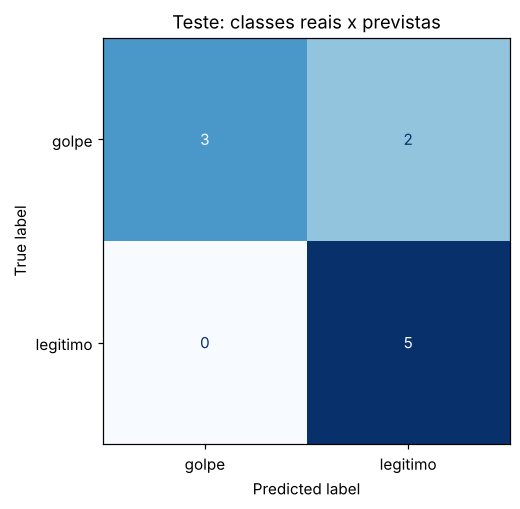

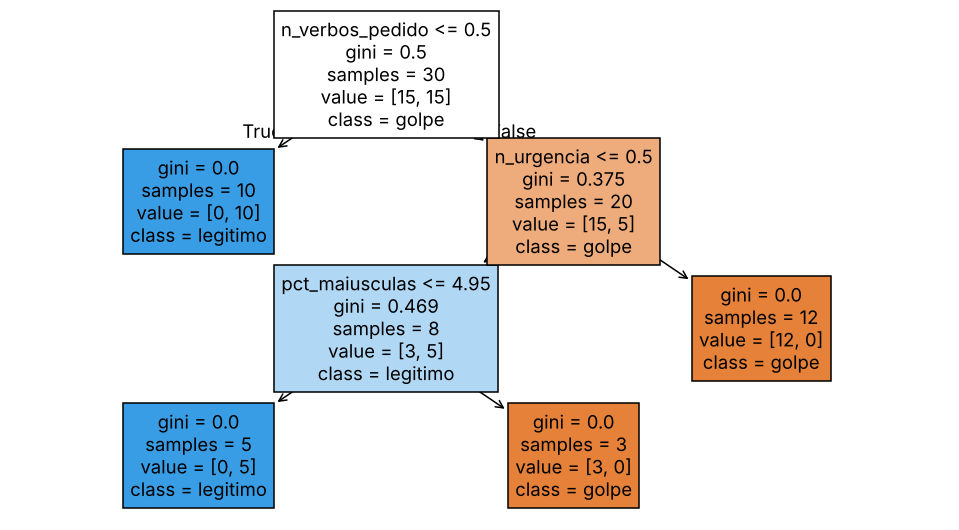

In [7]:
# Treinamento e avaliação
res = treinar_modelo(dados)
print("Treino:", len(res.X_treino), "| Teste:", len(res.X_teste))
print(f"Acurácia no teste: {res.acuracia:.1%}")
print(f"Validação cruzada (5 divisões): {res.cv_media:.1%} (+/- {res.cv_desvio:.1%})")

# Matriz de confusão em texto e em gráfico
print(pd.DataFrame(res.matriz, index=res.classes, columns=res.classes))
ConfusionMatrixDisplay(res.matriz, display_labels=res.classes).plot(cmap="Blues", colorbar=False)
plt.title("Teste: classes reais x previstas")
plt.show()

# Regras que a árvore aprendeu (em texto) e estrutura gráfica
print("Condições aprendidas:")
print(export_text(res.modelo, feature_names=ATRIBUTOS))
plt.figure(figsize=(11, 6))
plot_tree(res.modelo, feature_names=ATRIBUTOS, class_names=list(res.modelo.classes_), filled=True)
plt.show()

# Quais exemplos de TESTE o modelo errou? (olhar os erros ensina mais que olhar a acurácia)
analise = dados.loc[res.X_teste.index].assign(previsto=res.previsoes)
erros = analise[analise["perfil"] != analise["previsto"]]
print(f"\nExemplos de teste errados: {len(erros)} de {len(analise)}")
if len(erros):
    print(erros[["texto", "perfil", "previsto"]].to_string(index=False))
print(f"Acurácia no TREINO: {accuracy_score(res.y_treino, res.modelo.predict(res.X_treino)):.1%} "
      "(muito acima da do teste indica memorização, ou seja, overfitting)")

### Entendendo os termos da árvore de decisão

Cada caixa da árvore mostra três métricas:

1. **gini** mede a *impureza* do nó: `0.0` = todos os exemplos são da mesma classe; `0.5` = mistura máxima (duas classes).
2. **samples** é o número de exemplos de treino que chegaram àquele nó.
3. **value** é a contagem por classe, na ordem alfabética `[golpe, legitimo]`.

**Como ler os erros:** repare no tipo de mensagem que o modelo erra. Em geral são **golpes sem palavras de urgência ou sem link** (parecem mensagens comuns para quem só conta palavras). Isso mostra por que, neste projeto, o ML é **apenas um apoio**: quem decide são as regras do especialista e as respostas do usuário. Note também que a acurácia no treino costuma ser maior que no teste: é o sinal clássico de *overfitting*.

**Interpretação:** como as mensagens foram escritas por uma só pessoa e há apenas **10 casos de teste**, a acurácia **não demonstra eficácia em situações reais**; datasets pequenos geram árvores instáveis. A árvore mostra *condições aprendidas*; **as regras do sistema especialista abaixo foram escritas por pessoas**, com justificativa.

## 5. Base de conhecimento e motor de inferência (Fase 2)

A previsão do modelo vira **um fato**. Os demais fatos são informados pelo usuário. O motor procura as regras compatíveis, calcula o grau de suspeita e apresenta o plano de ação com justificativa.

### 5.1 Fatores de certeza (técnica do MYCIN)

Em vez de "golpe: sim/não", cada regra tem um **fator de certeza** (`cf`, de -1 a +1) e cada fato tem o seu grau de verdade. A contribuição de uma regra é `cf_da_regra × (menor certeza entre as premissas)`. Quando várias regras apoiam a mesma conclusão, as certezas são **combinadas**:

- duas evidências a favor: `a + b·(1 - a)` (nunca passa de 1);
- duas contra: `a + b·(1 + a)`;
- uma a favor e outra contra: `(a + b) / (1 - min(|a|, |b|))`.

Resposta "sim" vale `+1`, "não" vale `-1` e "não sei" deixa o fato **desconhecido** (o sistema não inventa dados).

In [8]:
# ----------------------------------------------------------------------
# Parâmetros do sistema
# ----------------------------------------------------------------------
LIMIAR = 0.2          # evidência mínima para considerar um fato "verdadeiro"
NIVEL_ALTO = 0.7      # suspeita >= 0.7  -> nível ALTO
NIVEL_MODERADO = 0.4  # suspeita >= 0.4  -> nível MODERADO
MIN_INFO = 4          # mínimo de sinais respondidos para concluir "baixo risco"

# De onde vem o CRITÉRIO de cada regra (justificativa da origem)
FONTES = {
    "FEB": "Orientações públicas da Febraban (campanha 'Pare & Pense #Pode ser Golpe' e dicas antigolpe)",
    "BCB": "Banco Central do Brasil (Mecanismo Especial de Devolução - MED do Pix)",
    "HEUR": "Heurística do autor, a validar com especialista",
    "ML": "Modelo de aprendizado de máquina (Fase 1)",
}


def combinar(a: float, b: float) -> float:
    """O QUE FAZ: combina dois fatores de certeza que apoiam a MESMA conclusão
    (fórmula do MYCIN). O resultado fica sempre entre -1 e +1."""
    if a >= 0 and b >= 0:
        return a + b * (1 - a)
    if a <= 0 and b <= 0:
        return a + b * (1 + a)
    den = 1 - min(abs(a), abs(b))
    return 0.0 if den < 1e-9 else (a + b) / den


def premissa_ok(cf: float, esperado: bool, limiar: float) -> bool:
    """O QUE FAZ: diz se uma premissa está satisfeita.
    Premissa 'verdadeira' exige cf >= limiar; premissa negada ('NÃO x') exige cf <= -limiar."""
    return cf >= limiar if esperado else cf <= -limiar

### 5.2 Base de Conhecimento, Memória de Trabalho e Motor de Inferência

- **`Regra`**: uma regra `SE premissas ENTÃO conclusão`, com `cf`, justificativa (`nota`) e `fonte`.
- **`BaseConhecimento`**: guarda perguntas, regras e textos; também **verifica** a si mesma.
- **`MemoriaTrabalho`**: guarda os fatos da consulta atual e a origem de cada um.
- **`MotorInferencia`**: faz o encadeamento para frente, o encadeamento para trás e a explicação.

In [9]:
@dataclass(frozen=True)
class Regra:
    """O QUE É: uma regra de produção do especialista: SE premissas ENTÃO conclusão.
    Campos: id (nome da regra), premissas (lista de (fato, esperado)), conclusao (fato
    produzido), cf (confiança da regra, -1..1), limiar (evidência mínima das premissas),
    nota (justificativa em português, usada na explicação) e fonte (origem do critério)."""
    id: str
    premissas: tuple
    conclusao: str
    cf: float
    limiar: float = LIMIAR
    nota: str = ""
    fonte: str = "HEUR"

    @staticmethod
    def criar(id: str, premissas: str, conclusao: str, cf: float, nota: str = "",
              limiar: float = LIMIAR, fonte: str = "HEUR") -> "Regra":
        """O QUE FAZ: atalho para escrever regras como texto.
        Exemplo: Regra.criar("S2", "a & !b", "suspeita", 0.7) -> SE a E NÃO b ENTÃO suspeita.
        O prefixo '!' significa que o fato precisa ser FALSO."""
        ps = tuple((p.strip().lstrip("!"), not p.strip().startswith("!"))
                   for p in premissas.split("&"))
        return Regra(id, ps, conclusao, cf, limiar, nota, fonte)

    def __str__(self) -> str:
        p = " E ".join(("" if e else "NÃO ") + f for f, e in self.premissas)
        return f"{self.id}: SE {p} ENTÃO {self.conclusao} (cf {self.cf:+.2f})"


class BaseConhecimento:
    """O QUE É: o conhecimento estático do especialista.
    Contém: perguntas (fatos que o usuário informa), regras, rótulos legíveis, tipos de
    golpe, ações recomendadas, fatos de saída e fatos externos (vindos do modelo de ML)."""

    def __init__(self, perguntas: dict, regras: list, rotulos: dict, tipos: dict,
                 acoes: dict, saidas: set, externos: frozenset = frozenset()):
        self.perguntas = perguntas      # fato -> texto da pergunta (sim/não)
        self.regras = regras
        self.rotulos = rotulos          # fato -> nome legível
        self.tipos = tipos              # fato -> nome do tipo de golpe
        self.acoes = acoes              # fato -> texto da ação (a ordem define a prioridade)
        self.saidas = saidas            # fatos que são resultado final
        self.externos = externos        # fatos fornecidos por fora (ex.: modelo de ML)

    def regras_que_concluem(self, fato: str) -> list:
        """Devolve as regras cuja conclusão é `fato` (usado no encadeamento para trás)."""
        return [r for r in self.regras if r.conclusao == fato]

    def verificar(self) -> dict:
        """O QUE FAZ: VERIFICAÇÃO da base (falhas lógicas internas), sem precisar de usuário.
        Procura: regras duplicadas, premissas inalcançáveis, ciclos de dependência,
        pesos inválidos e perguntas/fatos que nunca são usados."""
        rel = {"duplicadas": [], "inalcancaveis": [], "ciclos": [],
               "cf_invalido": [], "nao_usados": []}
        derivados = {r.conclusao for r in self.regras}
        usados = {f for r in self.regras for f, _ in r.premissas}

        for i, r1 in enumerate(self.regras):
            for r2 in self.regras[i + 1:]:
                if set(r1.premissas) == set(r2.premissas) and r1.conclusao == r2.conclusao:
                    rel["duplicadas"].append(f"{r1.id} e {r2.id} têm mesmas premissas e conclusão")
        for r in self.regras:
            if not (0 < abs(r.cf) <= 1) or not (0 < r.limiar <= 1):
                rel["cf_invalido"].append(f"{r.id}: cf={r.cf}, limiar={r.limiar}")
            for f, _ in r.premissas:
                if f not in self.perguntas and f not in derivados and f not in self.externos:
                    rel["inalcancaveis"].append(
                        f"{r.id}: '{f}' não é perguntável, externo nem concluído por regra")
        for f in list(self.perguntas) + list(self.externos):
            if f not in usados:
                rel["nao_usados"].append(f"'{f}' não é usado por nenhuma regra")
        for f in derivados:
            if f not in usados and f not in self.saidas:
                rel["nao_usados"].append(f"fato '{f}' é concluído mas nunca usado")

        grafo: dict = {}
        for r in self.regras:
            grafo.setdefault(r.conclusao, set()).update(f for f, _ in r.premissas)

        def tem_ciclo(no, visitando, feitos):
            if no in visitando:
                return True
            if no in feitos:
                return False
            visitando.add(no)
            if any(tem_ciclo(v, visitando, feitos) for v in grafo.get(no, ())):
                return True
            visitando.discard(no)
            feitos.add(no)
            return False

        feitos: set = set()
        for no in list(grafo):
            if tem_ciclo(no, set(), feitos):
                rel["ciclos"].append(f"ciclo de dependência envolvendo '{no}'")
                break
        return rel


@dataclass
class MemoriaTrabalho:
    """O QUE É: a memória DINÂMICA da consulta atual.
    `fatos` guarda o fator de certeza de cada fato; `origem` diz quem o produziu
    ("usuário", "regras" ou "modelo de ML"); `desconhecidos` lista o que o usuário
    respondeu "não sei" (para nunca perguntar duas vezes)."""
    fatos: dict = field(default_factory=dict)
    origem: dict = field(default_factory=dict)
    desconhecidos: set = field(default_factory=set)

    def afirmar(self, fato: str, cf: float, origem: str) -> None:
        """Registra (ou atualiza) um fato com seu fator de certeza e sua origem."""
        self.fatos[fato] = cf
        self.origem[fato] = origem

    def limpar(self) -> None:
        """Esvazia a memória para começar uma nova consulta."""
        self.fatos.clear()
        self.origem.clear()
        self.desconhecidos.clear()


Provedor = Callable[[str, str], Optional[str]]   # (fato, pergunta) -> "sim" | "nao" | None


class MotorInferencia:
    """O QUE É: o "cérebro" do sistema especialista. Não sabe nada sobre golpes:
    apenas cruza os fatos da Memória de Trabalho com as regras da Base de Conhecimento."""

    def __init__(self, bc: BaseConhecimento, mt: Optional[MemoriaTrabalho] = None):
        self.bc = bc
        self.mt = mt or MemoriaTrabalho()
        self.contribuicoes: dict = {}   # id da regra -> (fato, contribuição) [para explicar]
        self.perguntadas: list = []     # perguntas efetivamente feitas ao usuário

    def registrar_resposta(self, fato: str, resposta: Optional[str]) -> None:
        """Converte a resposta do usuário em fato: sim -> +1, nao -> -1, outro -> desconhecido."""
        if resposta == "sim":
            self.mt.afirmar(fato, 1.0, "usuário")
        elif resposta == "nao":
            self.mt.afirmar(fato, -1.0, "usuário")
        else:
            self.mt.desconhecidos.add(fato)

    def _contribuicao(self, r: Regra) -> Optional[float]:
        """Calcula quanto uma regra contribui (cf × menor certeza das premissas).
        Devolve None se alguma premissa não estiver satisfeita."""
        forcas = []
        for f, esperado in r.premissas:
            cf = self.mt.fatos.get(f)
            if cf is None or not premissa_ok(cf, esperado, r.limiar):
                return None
            forcas.append(abs(cf))
        return r.cf * min(forcas)

    def encadeamento_frente(self) -> list:
        """ENCADEAMENTO PARA FRENTE (dirigido por dados).
        Parte dos fatos já presentes na memória e recalcula todas as conclusões possíveis
        até estabilizar. Devolve a lista de regras que dispararam."""
        derivados = {r.conclusao for r in self.bc.regras}
        for _ in range(len(self.bc.regras) + 2):
            self.contribuicoes.clear()
            novos: dict = {}
            for fato in derivados:
                total = None
                for r in self.bc.regras_que_concluem(fato):
                    c = self._contribuicao(r)
                    if c is None:
                        continue
                    self.contribuicoes[r.id] = (fato, c)
                    total = c if total is None else combinar(total, c)
                if total is not None:
                    novos[fato] = total
            mudou = False
            for fato in derivados:
                antigo = self.mt.fatos.get(fato)
                if fato in novos:
                    if antigo is None or abs(antigo - novos[fato]) > 1e-9:
                        self.mt.afirmar(fato, novos[fato], "regras")
                        mudou = True
                elif antigo is not None and self.mt.origem.get(fato) == "regras":
                    del self.mt.fatos[fato]
                    del self.mt.origem[fato]
                    mudou = True
            if not mudou:
                break
        return list(self.contribuicoes)

    def avaliar(self, fato: str, provedor: Provedor,
                _pilha: frozenset = frozenset()) -> Optional[float]:
        """ENCADEAMENTO PARA TRÁS (dirigido por objetivos).
        Descobre o fator de certeza de `fato`: se já está na memória, usa; se há regras
        que o concluem, avalia as premissas (recursivamente) e combina as contribuições;
        se é uma pergunta, consulta o usuário via `provedor`. Devolve None quando o dado
        é desconhecido (caso INCOMPLETO). Se uma premissa falha, as demais premissas
        daquela regra NÃO são perguntadas (curto-circuito: só pergunta o necessário)."""
        if fato in self.mt.fatos:
            return self.mt.fatos[fato]
        if fato in self.mt.desconhecidos or fato in _pilha:
            return None
        regras = self.bc.regras_que_concluem(fato)
        if regras:
            pilha = _pilha | {fato}
            total = 0.0
            for r in regras:
                forcas, ok = [], True
                for f, esperado in r.premissas:
                    cf = self.avaliar(f, provedor, pilha)
                    if cf is None or not premissa_ok(cf, esperado, r.limiar):
                        ok = False
                        break
                    forcas.append(abs(cf))
                if ok:
                    c = r.cf * min(forcas)
                    self.contribuicoes[r.id] = (fato, c)
                    total = combinar(total, c)
            self.mt.afirmar(fato, total, "regras")
            return total
        if fato in self.bc.perguntas:
            self.perguntadas.append(fato)
            self.registrar_resposta(fato, provedor(fato, self.bc.perguntas[fato]))
            return self.mt.fatos.get(fato)
        return None

    def explicar(self) -> str:
        """EXPLICAÇÃO ("como cheguei a isso"): lista as evidências informadas, o que o
        modelo de ML achou e as regras que pesaram, com a justificativa e a fonte de cada uma.
        É a transparência que distingue sistemas especialistas de uma "caixa-preta"."""
        rot = self.bc.rotulos
        regras = {r.id: r for r in self.bc.regras}
        linhas = ["Evidências informadas por você:"]
        sim = [rot.get(f, f) for f, cf in self.mt.fatos.items()
               if self.mt.origem[f] == "usuário" and cf > 0]
        linhas += [f"  - {s}" for s in sim] or ["  - (nenhum sinal de alerta confirmado)"]
        if "ml_golpe" in self.mt.fatos:
            p = (self.mt.fatos["ml_golpe"] + 1) / 2
            linhas.append(f"Leitura do texto pelo modelo de ML: {p:.0%} de chance de ser golpe.")

        evid, susp, tipo = [], [], []
        for rid, (fato, c) in self.contribuicoes.items():
            r = regras[rid]
            if fato.startswith("i_") and fato != "i_houve_dano":
                evid.append(f"  - {rid}: {rot.get(fato, fato)} ({c:.0%}). {r.nota} [fonte: {r.fonte}]")
            elif fato == "suspeita_golpe":
                sinal = "aumenta" if c > 0 else "reduz"
                susp.append(f"  - {rid} ({sinal} a suspeita em {abs(c):.0%}): {r.nota} [fonte: {r.fonte}]")
            elif fato in self.bc.tipos:
                tipo.append(f"  - {rid}: indica '{self.bc.tipos[fato]}' ({c:.0%}). {r.nota} [fonte: {r.fonte}]")
        for titulo, itens in (("Evidências deduzidas:", evid),
                              ("Regras que pesaram na suspeita:", susp),
                              ("Regras que indicam o tipo de golpe:", tipo)):
            if itens:
                linhas.append(titulo)
                linhas += itens
        if not (evid or susp or tipo):
            linhas.append("Nenhuma regra de alerta foi acionada.")
        return "\n".join(linhas)

### 5.3 A base de conhecimento de golpes (regras e justificativa de origem)

São **13 perguntas de sinais**, **6 perguntas sobre o que a pessoa já fez**, **1 fato vindo do modelo de ML** (`ml_golpe`) e **mais de 50 regras**, em camadas:

1. **Evidências** (`I`): sinais brutos viram evidências (ex.: pediu código → *pede credencial*);
2. **Suspeita** (`S`) e **ML** (`M`): evidências viram o grau de suspeita;
3. **Tipo de golpe** (`T`): classifica o golpe (conta segura, motoboy, acesso remoto, código/senha, phishing, falsa oferta);
4. **Nível** (`N`), **danos** (`D`) e **plano de ação** (`A`): só perguntados se houver suspeita.

**Origem das regras (item 2 da atividade):** o campo `fonte` de cada regra indica de onde vem o *critério* (`FEB` = orientações públicas da Febraban; `BCB` = Banco Central; `HEUR` = heurística do autor; `ML` = modelo). **Os valores numéricos (`cf`) foram calibrados pelo autor** e precisam de validação por um especialista em fraudes.

Exemplos de critérios com fonte pública: banco **nunca** pede senha, código ou transferência; banco **não** manda motoboy buscar cartão; na dúvida, **desligar e ligar para o número oficial, de preferência de outro aparelho**; não clicar em links de "atualização de cadastro".

In [10]:
def criar_bc_golpes() -> BaseConhecimento:
    """O QUE FAZ: constrói a Base de Conhecimento do domínio "golpes de falsa central".
    Para usar o motor em outro assunto, basta escrever outra função como esta."""
    perguntas = {
        # ---- sinais do contato ----
        "s_contato_inesperado": "Você foi contatado sem ter pedido nada (ligação, SMS, WhatsApp ou e-mail)?",
        "s_numero_nao_oficial": "O número ou remetente é diferente do oficial (verso do cartão, app ou site)?",
        "s_urgencia": "Falaram em urgência, bloqueio da conta ou prazo curto para você agir?",
        "s_cita_compra_suspeita": "Disseram que houve uma compra ou movimentação suspeita na sua conta?",
        "s_pede_codigo": "Pediram algum código (SMS, token, e-mail ou do aplicativo)?",
        "s_pede_senha": "Pediram senha, CVV ou a senha do cartão?",
        "s_pede_app_remoto": "Pediram para instalar um aplicativo ou liberar acesso remoto ao seu celular/computador?",
        "s_pede_transferencia": "Pediram Pix, transferência ou depósito (por exemplo, para uma 'conta segura')?",
        "s_pede_entregar_cartao": "Disseram que alguém iria buscar ou que você deveria entregar seu cartão?",
        "s_link": "Enviaram um link para 'regularizar', 'desbloquear' ou 'atualizar cadastro'?",
        "s_promessa_beneficio": "Ofereceram prêmio, aumento de limite, cashback ou desconto?",
        "s_pede_pagar_taxa": "Pediram pagamento de taxa, boleto ou tarifa para liberar algo?",
        "s_voce_iniciou": "Foi VOCÊ quem iniciou o contato, ligando para o número oficial (cartão, app ou site)?",
        # ---- o que a pessoa já fez (só perguntado se houver suspeita) ----
        "a_passou_codigo": "Você chegou a informar algum código?",
        "a_passou_senha": "Você chegou a informar senha ou CVV?",
        "a_instalou_app": "Você instalou o aplicativo ou liberou o acesso remoto?",
        "a_fez_transferencia": "Você chegou a fazer Pix, transferência ou pagamento?",
        "a_entregou_cartao": "Você entregou o cartão (ou deixou alguém buscá-lo)?",
        "a_clicou_link": "Você clicou no link ou preencheu dados nele?",
    }
    rotulos = {
        "s_contato_inesperado": "contato que você não solicitou",
        "s_numero_nao_oficial": "número/remetente não oficial",
        "s_urgencia": "urgência ou ameaça de bloqueio",
        "s_cita_compra_suspeita": "alegação de compra suspeita",
        "s_pede_codigo": "pedido de código",
        "s_pede_senha": "pedido de senha/CVV",
        "s_pede_app_remoto": "pedido de app de acesso remoto",
        "s_pede_transferencia": "pedido de Pix/transferência",
        "s_pede_entregar_cartao": "pedido para entregar o cartão",
        "s_link": "link para 'regularizar'",
        "s_promessa_beneficio": "promessa de prêmio/benefício",
        "s_pede_pagar_taxa": "cobrança de taxa",
        "s_voce_iniciou": "você iniciou o contato pelo canal oficial",
        "a_passou_codigo": "você informou um código",
        "a_passou_senha": "você informou senha/CVV",
        "a_instalou_app": "você instalou o app de acesso remoto",
        "a_fez_transferencia": "você fez Pix/transferência",
        "a_entregou_cartao": "você entregou o cartão",
        "a_clicou_link": "você clicou no link",
        "i_pressao": "pressão psicológica",
        "i_pede_credencial": "pedido de credencial",
        "i_canal_nao_oficial": "canal não oficial",
        "i_pede_acao_financeira": "pedido de ação financeira",
        "i_pede_acesso_remoto": "pedido de acesso remoto",
        "ml_golpe": "análise do texto pelo modelo de ML",
    }
    tipos = {
        "t_conta_segura": "Golpe da 'conta segura' (falsa central de segurança)",
        "t_motoboy": "Golpe do motoboy (retirada do cartão)",
        "t_acesso_remoto": "Golpe do acesso remoto (aplicativo espião)",
        "t_roubo_credenciais": "Roubo de código ou senha (engenharia social)",
        "t_phishing_link": "Phishing por link (site falso)",
        "t_falsa_oferta": "Falsa oferta ou prêmio (cobrança de taxa)",
    }
    acoes = {   # a ordem define a prioridade na tela
        "ac_contestar_pix": "URGENTE: ligue agora para o banco pelo canal oficial (verso do cartão ou app) e peça a contestação do Pix pelo MED (Mecanismo Especial de Devolução). O pedido tem prazo (confirme o atual no site do Banco Central) e, quanto antes for feito, maiores as chances de bloquear o valor, pois isso depende de ainda haver saldo na conta de quem recebeu.",
        "ac_bloquear_cartao": "URGENTE: bloqueie o cartão pelo app ou pela central oficial e solicite um novo. Não entregue o cartão a ninguém que apareça para 'buscar'.",
        "ac_remover_app": "URGENTE: desinstale o aplicativo de acesso remoto, desligue a internet do aparelho e confirme com o banco, pelo canal oficial, se houve movimentação. Se possível, restaure o aparelho de fábrica.",
        "ac_trocar_senha": "Troque agora as senhas do banco e do e-mail, encerre sessões/dispositivos conectados e, se informou a senha do cartão, peça a troca ou o bloqueio.",
        "ac_ligar_banco": "Avise o banco, pelo canal oficial, que você foi alvo de golpe, para que ele reforce a proteção da sua conta.",
        "ac_bo": "Registre boletim de ocorrência (delegacia virtual do seu estado) e guarde prints, números de telefone, horários e comprovantes.",
        "ac_monitorar": "Ative alertas de transações e acompanhe o extrato nos próximos dias; desconfie de novos contatos sobre o mesmo assunto.",
        "ac_encerrar": "Encerre o contato agora (desligue ou pare de responder) e não siga nenhuma instrução recebida.",
        "ac_canal_oficial": "Para confirmar, desligue e ligue você mesmo para o número oficial do verso do cartão ou do aplicativo, de preferência de outro aparelho (o golpista pode manter a linha aberta); nunca retorne para o número que te procurou.",
        "ac_bloquear_denunciar": "Bloqueie o número ou remetente e denuncie na própria plataforma (WhatsApp, SMS, e-mail).",
    }
    R = Regra.criar
    FEB, BCB, HEUR, ML = "FEB", "BCB", "HEUR", "ML"
    regras = [
        # --- sinais -> evidências intermediárias ---
        R("I1", "s_urgencia & s_contato_inesperado", "i_pressao", 0.9,
          "contato não solicitado com urgência é a tática central: o golpista quer que você aja antes de pensar.", fonte=HEUR),
        R("I2", "s_urgencia", "i_pressao", 0.6,
          "urgência e ameaça de bloqueio são usadas para impedir que você confirme a história.", fonte=HEUR),
        R("I3", "s_pede_codigo", "i_pede_credencial", 0.9,
          "banco e operadora nunca pedem o código recebido por SMS, token ou aplicativo.", fonte=FEB),
        R("I4", "s_pede_senha", "i_pede_credencial", 0.95,
          "nenhuma instituição legítima pede senha completa, CVV ou senha do cartão.", fonte=FEB),
        R("I5", "s_numero_nao_oficial", "i_canal_nao_oficial", 0.7,
          "o contato não veio de um canal que você possa confirmar como oficial (o número pode ser falsificado).", fonte=FEB),
        R("I6", "s_link", "i_canal_nao_oficial", 0.6,
          "links de 'regularização' ou 'atualização de cadastro' enviados por mensagem são a principal porta do phishing.", fonte=FEB),
        R("I7", "s_pede_transferencia", "i_pede_acao_financeira", 0.95,
          "não existe 'conta segura': nenhum banco manda você transferir dinheiro para protegê-lo.", fonte=FEB),
        R("I8", "s_pede_pagar_taxa", "i_pede_acao_financeira", 0.7,
          "cobrar taxa para liberar benefício ou desbloquear conta é típico de golpe.", fonte=HEUR),
        R("I9", "s_pede_app_remoto", "i_pede_acesso_remoto", 0.95,
          "apps de acesso remoto deixam o golpista operar seu celular e o app do banco (golpe da 'mão fantasma').", fonte=FEB),
        # --- evidências -> suspeita de golpe ---
        R("S1", "i_pressao & i_pede_credencial", "suspeita_golpe", 0.9,
          "pressão de tempo somada a pedido de credencial é o padrão clássico de golpe.", fonte=HEUR),
        R("S2", "i_pede_credencial", "suspeita_golpe", 0.75,
          "pedir código ou senha, por si só, já é sinal forte de golpe.", fonte=FEB),
        R("S3", "i_pede_acao_financeira", "suspeita_golpe", 0.8,
          "pedido de movimentação de dinheiro iniciado pelo atendente é sinal forte de golpe.", fonte=FEB),
        R("S4", "i_pede_acesso_remoto", "suspeita_golpe", 0.9,
          "pedido de acesso remoto é um dos sinais mais graves.", fonte=FEB),
        R("S5", "i_pressao & i_canal_nao_oficial", "suspeita_golpe", 0.7,
          "urgência vinda de canal não oficial indica tentativa de induzir ação precipitada.", fonte=HEUR),
        R("S6", "s_cita_compra_suspeita & i_canal_nao_oficial", "suspeita_golpe", 0.6,
          "'compra suspeita' por canal não oficial é o gancho mais usado pela falsa central.", fonte=FEB),
        R("S7", "s_cita_compra_suspeita & s_contato_inesperado", "suspeita_golpe", 0.4,
          "bancos reais também avisam sobre fraude, por isso o peso é só moderado sem outros sinais.", fonte=HEUR),
        R("S8", "s_pede_entregar_cartao", "suspeita_golpe", 0.95,
          "bancos não enviam motoboy para buscar cartão: isso é golpe.", fonte=FEB),
        R("S9", "s_promessa_beneficio & s_link", "suspeita_golpe", 0.7,
          "prêmio ou benefício acompanhado de link é padrão de phishing.", fonte=HEUR),
        R("S10", "s_promessa_beneficio & s_contato_inesperado", "suspeita_golpe", 0.45,
          "ofertas que você não pediu merecem desconfiança.", fonte=HEUR),
        R("S11", "s_pede_pagar_taxa & s_promessa_beneficio", "suspeita_golpe", 0.8,
          "pagar para receber prêmio ou liberação é o roteiro da falsa oferta.", fonte=HEUR),
        R("S12", "s_voce_iniciou & !s_numero_nao_oficial", "suspeita_golpe", -0.4,
          "você ligou para o número oficial, o que reduz o risco (mas golpistas podem manter a linha aberta; nunca informe código ou senha).", fonte=FEB),
        # --- Fase 1 (modelo de ML) -> suspeita ---
        R("M1", "ml_golpe", "suspeita_golpe", 0.5,
          "o modelo de ML, treinado com mensagens simuladas, achou o texto parecido com golpes (peso moderado: é só um apoio).", fonte=ML),
        R("M2", "!ml_golpe", "suspeita_golpe", -0.2,
          "o modelo achou o texto parecido com mensagens legítimas (peso baixo: ligações de golpe não têm texto).", fonte=ML),
        # --- tipo de golpe ---
        R("T1", "s_cita_compra_suspeita & i_pede_acao_financeira", "t_conta_segura", 0.9,
          "compra suspeita + pedido de transferência é o golpe da conta segura.", fonte=FEB),
        R("T2", "s_pede_transferencia & s_urgencia", "t_conta_segura", 0.6,
          "pedido urgente de transferência lembra o golpe da conta segura.", fonte=HEUR),
        R("T3", "s_pede_entregar_cartao", "t_motoboy", 0.95,
          "retirada do cartão por portador é o golpe do motoboy.", fonte=FEB),
        R("T4", "s_pede_entregar_cartao & s_cita_compra_suspeita", "t_motoboy", 0.9,
          "o motoboy costuma vir após a história da compra suspeita.", fonte=FEB),
        R("T5", "i_pede_acesso_remoto", "t_acesso_remoto", 0.9,
          "instalação de app de acesso remoto caracteriza o golpe do acesso remoto.", fonte=FEB),
        R("T6", "s_pede_codigo", "t_roubo_credenciais", 0.8,
          "o código serve para o golpista entrar na sua conta ou clonar seu WhatsApp.", fonte=FEB),
        R("T7", "s_pede_senha", "t_roubo_credenciais", 0.8,
          "senha ou CVV permitem acesso direto às suas contas e ao cartão.", fonte=FEB),
        R("T8", "s_link & i_canal_nao_oficial", "t_phishing_link", 0.8,
          "link por canal não oficial costuma levar a site falso que captura dados.", fonte=FEB),
        R("T9", "s_link", "t_phishing_link", 0.5,
          "qualquer link de regularização pode levar a site falso.", fonte=HEUR),
        R("T10", "s_promessa_beneficio & s_pede_pagar_taxa", "t_falsa_oferta", 0.9,
          "prêmio condicionado a pagamento de taxa é a falsa oferta.", fonte=HEUR),
        R("T11", "s_promessa_beneficio", "t_falsa_oferta", 0.5,
          "promessa de benefício não solicitado sugere falsa oferta.", fonte=HEUR),
        # --- nível de alerta (usado pelo plano de ação) ---
        R("N1", "suspeita_golpe", "f_alerta", 1.0, "suspeita moderada ou alta.",
          limiar=NIVEL_MODERADO, fonte=HEUR),
        # --- danos já ocorridos (só perguntados se houver alerta) ---
        R("D1", "f_alerta & a_passou_codigo", "i_houve_dano", 1.0),
        R("D2", "f_alerta & a_passou_senha", "i_houve_dano", 1.0),
        R("D3", "f_alerta & a_instalou_app", "i_houve_dano", 1.0),
        R("D4", "f_alerta & a_fez_transferencia", "i_houve_dano", 1.0),
        R("D5", "f_alerta & a_entregou_cartao", "i_houve_dano", 1.0),
        R("D6", "f_alerta & a_clicou_link", "i_houve_dano", 1.0),
        # --- plano de ação ---
        R("A1", "f_alerta & a_fez_transferencia", "ac_contestar_pix", 1.0, fonte=BCB),
        R("A2", "f_alerta & a_entregou_cartao", "ac_bloquear_cartao", 1.0, fonte=FEB),
        R("A3", "f_alerta & a_instalou_app", "ac_remover_app", 1.0, fonte=FEB),
        R("A4", "f_alerta & a_passou_senha", "ac_trocar_senha", 1.0, fonte=FEB),
        R("A5", "f_alerta & a_passou_codigo", "ac_trocar_senha", 1.0, fonte=FEB),
        R("A6", "f_alerta & a_clicou_link", "ac_trocar_senha", 0.9, fonte=HEUR),
        R("A7", "i_houve_dano", "ac_ligar_banco", 1.0, fonte=FEB),
        R("A8", "i_houve_dano", "ac_bo", 1.0, fonte=HEUR),
        R("A9", "i_houve_dano", "ac_monitorar", 1.0, fonte=HEUR),
        R("A10", "f_alerta", "ac_encerrar", 1.0, fonte=FEB),
        R("A11", "f_alerta", "ac_canal_oficial", 1.0, fonte=FEB),
        R("A12", "f_alerta", "ac_bloquear_denunciar", 1.0, fonte=HEUR),
    ]
    saidas = {"suspeita_golpe", *tipos, *acoes}
    return BaseConhecimento(perguntas, regras, rotulos, tipos, acoes, saidas,
                            externos=frozenset({"ml_golpe"}))

In [11]:
# Exibição da base de conhecimento
bc = criar_bc_golpes()
print(f"{len(bc.perguntas)} perguntas | {len(bc.regras)} regras | {len(bc.tipos)} tipos de golpe | {len(bc.acoes)} ações\n")
print("Algumas regras (com a fonte do critério):")
for r in [x for x in bc.regras if x.id in ("I3", "S2", "S8", "S12", "M1", "T3", "A1")]:
    print(f"  {r}   [fonte: {r.fonte} - {FONTES[r.fonte][:55]}...]")

19 perguntas | 53 regras | 6 tipos de golpe | 10 ações

Algumas regras (com a fonte do critério):
  I3: SE s_pede_codigo ENTÃO i_pede_credencial (cf +0.90)   [fonte: FEB - Orientações públicas da Febraban (campanha 'Pare & Pens...]
  S2: SE i_pede_credencial ENTÃO suspeita_golpe (cf +0.75)   [fonte: FEB - Orientações públicas da Febraban (campanha 'Pare & Pens...]
  S8: SE s_pede_entregar_cartao ENTÃO suspeita_golpe (cf +0.95)   [fonte: FEB - Orientações públicas da Febraban (campanha 'Pare & Pens...]
  S12: SE s_voce_iniciou E NÃO s_numero_nao_oficial ENTÃO suspeita_golpe (cf -0.40)   [fonte: FEB - Orientações públicas da Febraban (campanha 'Pare & Pens...]
  M1: SE ml_golpe ENTÃO suspeita_golpe (cf +0.50)   [fonte: ML - Modelo de aprendizado de máquina (Fase 1)...]
  T3: SE s_pede_entregar_cartao ENTÃO t_motoboy (cf +0.95)   [fonte: FEB - Orientações públicas da Febraban (campanha 'Pare & Pens...]
  A1: SE f_alerta E a_fez_transferencia ENTÃO ac_contestar_pix (cf +1.00)   [fonte: BCB

## 6. Integrar o modelo ao sistema especialista

1. **`classificar_mensagem`** roda a Fase 1: extrai os atributos do texto e usa o modelo treinado para prever `golpe` ou `legitimo`. Ela também **avisa** se os atributos estão fora dos intervalos vistos no treino (previsão menos confiável).
2. **`prob_para_cf`** converte a probabilidade do modelo em fator de certeza: `cf = (p - 0.5) × 2`, ou seja, 50% vira 0 (neutro), 100% vira +1 e 0% vira -1.
3. **`diagnosticar`** executa a Fase 2 com encadeamento para trás: avalia a suspeita, o tipo de golpe e o plano de ação, perguntando só o necessário.
4. **`analisar_contato`** une as duas fases (equivale à `orientar_estudante` do exemplo da disciplina).

O resultado **sempre** vem com aviso de revisão humana, conforme o tratado: a decisão final precisa ser auditável.

In [12]:
_RESULTADO_PADRAO: Optional[ResultadoTreino] = None


def obter_resultado_padrao() -> ResultadoTreino:
    """Treina o modelo padrão uma única vez e reaproveita nas próximas chamadas."""
    global _RESULTADO_PADRAO
    if _RESULTADO_PADRAO is None:
        _RESULTADO_PADRAO = treinar_modelo(construir_dataset())
    return _RESULTADO_PADRAO


def prob_para_cf(p_golpe: float) -> float:
    """O QUE FAZ: converte probabilidade (0 a 1) em fator de certeza (-1 a +1).
    50% -> 0 (modelo não sabe); 100% -> +1; 0% -> -1."""
    return max(-1.0, min(1.0, (p_golpe - 0.5) * 2))


def classificar_mensagem(texto: str, resultado: Optional[ResultadoTreino] = None) -> dict:
    """FASE 1 (machine learning). O QUE FAZ: classifica o texto de uma mensagem.
    Devolve: classe prevista, probabilidade de golpe, atributos calculados e um
    indicador `fora_do_intervalo` (True se algum atributo está fora do que o modelo viu
    no treino, caso em que a previsão é menos confiável)."""
    resultado = resultado or obter_resultado_padrao()
    atrib = extrair_atributos(texto)
    x = pd.DataFrame([atrib])[ATRIBUTOS]
    probas = dict(zip(resultado.modelo.classes_, resultado.modelo.predict_proba(x)[0]))
    p_golpe = float(probas.get("golpe", 0.0))
    fora = any(not (resultado.X_treino[c].min() <= atrib[c] <= resultado.X_treino[c].max())
               for c in ATRIBUTOS)
    return {"classe": "golpe" if p_golpe >= 0.5 else "legitimo",
            "prob_golpe": p_golpe, "atributos": atrib, "fora_do_intervalo": fora}


@dataclass
class Diagnostico:
    """O QUE É: o resultado final entregue ao usuário.
    suspeita (0 a 1), nivel (ALTO/MODERADO/BAIXO/INCOMPLETO), tipos [(nome, certeza)],
    acoes (em ordem de prioridade), explicacao (texto), perguntas_feitas, ml (saída da
    Fase 1, se houve texto) e aviso (sempre presente: revisão humana)."""
    suspeita: float
    nivel: str
    tipos: list
    acoes: list
    explicacao: str
    perguntas_feitas: int
    ml: Optional[dict] = None
    aviso: str = ""


ORIENTACAO_BAIXO = ("Não há indícios fortes de golpe nas suas respostas. Mesmo assim: "
                    "banco e operadora nunca pedem senha, CVV nem códigos recebidos por "
                    "SMS/aplicativo. Na dúvida, confirme pelo canal oficial.")
ORIENTACAO_INCOMPLETO = ("Informações insuficientes para concluir. Responda mais perguntas "
                         "ou, na dúvida, confirme pelo canal oficial e não compartilhe "
                         "códigos nem senhas.")


def classificar_nivel(cf: float, sinais_conhecidos: int) -> str:
    """O QUE FAZ: transforma o fator de certeza em nível: >=0.7 ALTO; >=0.4 MODERADO;
    abaixo disso BAIXO, mas só se houver informação suficiente (senão INCOMPLETO).
    Isso evita declarar "seguro" quando o usuário respondeu quase tudo "não sei"."""
    if cf >= NIVEL_ALTO:
        return "ALTO"
    if cf >= NIVEL_MODERADO:
        return "MODERADO"
    return "INCOMPLETO" if sinais_conhecidos < MIN_INFO else "BAIXO"


def diagnosticar(bc: BaseConhecimento, provedor: Provedor,
                 motor: Optional[MotorInferencia] = None) -> tuple:
    """FASE 2 (sistema especialista). O QUE FAZ: objetivo 1) suspeita de golpe;
    objetivo 2) tipo de golpe; objetivo 3) plano de ação. Cada objetivo é resolvido por
    encadeamento para trás, perguntando ao usuário (`provedor`) apenas o necessário.
    Perguntas sobre danos (a_*) só aparecem quando há alerta."""
    motor = motor or MotorInferencia(bc)
    suspeita = motor.avaliar("suspeita_golpe", provedor) or 0.0
    conhecidos = sum(1 for f in motor.mt.fatos
                     if f.startswith("s_") and motor.mt.origem[f] == "usuário")
    nivel = classificar_nivel(suspeita, conhecidos)

    tipos, acoes = [], []
    if nivel in ("ALTO", "MODERADO"):
        for t, nome in bc.tipos.items():
            cf = motor.avaliar(t, provedor) or 0.0
            if cf >= NIVEL_MODERADO:
                tipos.append((nome, cf))
        tipos.sort(key=lambda x: -x[1])
        for a, texto in bc.acoes.items():
            if (motor.avaliar(a, provedor) or 0.0) >= LIMIAR:
                acoes.append(texto)
    elif nivel == "BAIXO":
        acoes.append(ORIENTACAO_BAIXO)
    else:
        acoes.append(ORIENTACAO_INCOMPLETO)

    return Diagnostico(max(suspeita, 0.0), nivel, tipos, acoes,
                       motor.explicar(), len(motor.perguntadas)), motor


def analisar_contato(bc: BaseConhecimento, provedor: Provedor, texto: Optional[str] = None,
                     resultado: Optional[ResultadoTreino] = None) -> tuple:
    """INTEGRAÇÃO das duas fases. O QUE FAZ: se há texto, roda o modelo de ML e coloca a
    previsão na Memória de Trabalho como o fato dinâmico `ml_golpe`; depois roda o sistema
    especialista. Devolve (diagnostico, motor)."""
    motor = MotorInferencia(bc)
    ml = None
    if texto and texto.strip():
        ml = classificar_mensagem(texto, resultado)
        motor.mt.afirmar("ml_golpe", prob_para_cf(ml["prob_golpe"]), "modelo de ML")
    diag, motor = diagnosticar(bc, provedor, motor)
    diag.ml = ml
    diag.aviso = ("Entrada fora dos intervalos observados no treino: a leitura do modelo "
                  "pode ser menos confiável. Orientação sujeita a revisão humana."
                  if ml and ml["fora_do_intervalo"]
                  else "Exemplo didático; orientação sujeita a revisão humana.")
    return diag, motor

## 7. Interface de consulta

`provedor_cli` faz as perguntas no terminal ou no Colab (campo de texto abaixo da célula). `mostrar` imprime o resultado. `main` roda o ciclo completo de consultas.

In [13]:
def provedor_cli(fato: str, pergunta: str) -> Optional[str]:
    """Pergunta ao usuário e converte a resposta: s/sim -> "sim"; n/não -> "nao"; Enter -> None (não sei)."""
    while True:
        r = input(f"{pergunta} [s/n, Enter = não sei]: ").strip().lower()
        if r == "":
            return None
        if r in ("s", "sim"):
            return "sim"
        if r in ("n", "nao", "não"):
            return "nao"
        print("  Responda s, n ou Enter.")


def mostrar(d: Diagnostico) -> None:
    """Imprime o resultado: grau de suspeita, leitura do ML, tipo, plano de ação, explicação e aviso."""
    print("\n" + "=" * 62)
    print(f"GRAU DE SUSPEITA: {d.nivel}" +
          (f" ({d.suspeita:.0%})" if d.nivel != "INCOMPLETO" else ""))
    if d.ml:
        print(f"Modelo de ML (texto): {d.ml['classe']} ({d.ml['prob_golpe']:.0%} de chance de golpe)")
    if d.tipos:
        print("\nTipo provável:")
        for nome, cf in d.tipos:
            print(f"  - {nome} ({cf:.0%})")
    print("\nO que fazer:")
    for i, a in enumerate(d.acoes, 1):
        print(f"  {i}. {a}")
    print("\n" + d.explicacao)
    print(f"\nAviso: {d.aviso}")
    print("=" * 62)


def main() -> None:
    """Ciclo de consultas: (opcional) cola o texto da mensagem; responde às perguntas; vê o resultado."""
    bc = criar_bc_golpes()
    problemas = {k: v for k, v in bc.verificar().items() if v}
    if problemas:
        print("Aviso: falhas na base de conhecimento:", problemas)
    print("=== Triagem de golpes: falsa central de atendimento ===")
    print("Ferramenta educacional de apoio. Não substitui o banco ou a operadora.\n")
    while True:
        texto = input("Cole o texto da mensagem recebida (Enter para pular): ")
        d, _ = analisar_contato(bc, provedor_cli, texto)
        mostrar(d)
        if input("\nNova consulta? [s/n]: ").strip().lower() not in ("s", "sim"):
            break

## 8. Verificação da base de conhecimento

A **verificação** procura falhas lógicas internas: regras duplicadas, premissas impossíveis, ciclos, pesos inválidos e itens nunca usados. Lista vazia significa que nada foi encontrado.

In [14]:
bc = criar_bc_golpes()
for categoria, achados in bc.verificar().items():
    print(f"{categoria}: {achados or 'ok'}")

duplicadas: ok
inalcancaveis: ok
ciclos: ok
cf_invalido: ok
nao_usados: ok


## 9. Encadeamento para frente e casos de teste

### 9.1 Encadeamento para frente (dirigido por dados)
Colocamos fatos na memória e o motor deduz tudo o que for possível, sem perguntar nada.

In [15]:
mt = MemoriaTrabalho()
motor = MotorInferencia(bc, mt)
for fato, resp in {"s_pede_codigo": "sim", "s_urgencia": "sim", "s_contato_inesperado": "sim"}.items():
    motor.registrar_resposta(fato, resp)
print("Regras disparadas:", motor.encadeamento_frente())
print(f"suspeita_golpe = {mt.fatos['suspeita_golpe']:.0%}")
print(f"tipo roubo de credenciais = {mt.fatos['t_roubo_credenciais']:.0%}")

Regras disparadas: ['A12', 'N1', 'A10', 'I1', 'I2', 'A11', 'T6', 'I3', 'S1', 'S2']
suspeita_golpe = 94%
tipo roubo de credenciais = 80%


### 9.2 Casos de teste (positivo, negativo e incompleto)

| Tipo | Condição | Resultado esperado |
|---|---|---|
| **Positivo** | vários sinais de golpe presentes | suspeita ALTA, tipo correto e plano de ação |
| **Negativo** | nenhum sinal de golpe (ex.: SMS informativo) | suspeita BAIXA e nenhum alarme falso |
| **Incompleto** | o usuário não sabe responder | sistema avisa que faltam dados, **sem inventar** resposta |
| **Difícil (híbrido)** | o modelo de ML erra, mas o usuário informa um sinal forte | as **regras corrigem** o ML e o alerta é ALTO |

Cada caso usa `analisar_contato` (Fase 1 + Fase 2). As respostas são simuladas por um dicionário; o que não está nele conta como "não sei".

In [16]:
def simular(nome, texto, respostas):
    """Roda o sistema completo com texto e respostas prontas (o que falta = 'não sei')."""
    print(f"\n##### CENÁRIO: {nome}")
    d, _ = analisar_contato(bc, lambda fato, pergunta: respostas.get(fato), texto)
    mostrar(d)

# CASO POSITIVO: falsa central + Pix (a pessoa já transferiu)
simular("POSITIVO - falsa central + Pix",
        "Sou da central de segurança. Sua conta foi invadida. Faça um Pix para uma conta segura agora!",
        {"s_contato_inesperado": "sim", "s_numero_nao_oficial": "sim", "s_urgencia": "sim",
         "s_cita_compra_suspeita": "sim", "s_pede_transferencia": "sim",
         "a_fez_transferencia": "sim"})

# CASO NEGATIVO: SMS informativo legítimo
simular("NEGATIVO - SMS informativo",
        "Compra aprovada no cartão final 5678, R$ 32,00, em Padaria Exemplo.",
        {"s_contato_inesperado": "sim", "s_numero_nao_oficial": "nao", "s_urgencia": "nao",
         "s_cita_compra_suspeita": "nao", "s_pede_codigo": "nao", "s_pede_senha": "nao",
         "s_pede_app_remoto": "nao", "s_pede_transferencia": "nao",
         "s_pede_entregar_cartao": "nao", "s_link": "nao", "s_promessa_beneficio": "nao",
         "s_pede_pagar_taxa": "nao", "s_voce_iniciou": "nao"})

# CASO INCOMPLETO: nenhuma informação
simular("INCOMPLETO - usuário não sabe responder", None, {})

# CASO DIFÍCIL: o modelo de ML ERRA (acha a mensagem legítima), mas as regras acertam
simular("DIFÍCIL - ML erra, regras compensam",
        "Ligamos para avisar que um motoboy vai retirar seu cartão.",
        {"s_contato_inesperado": "sim", "s_pede_entregar_cartao": "sim", "a_entregou_cartao": "nao"})


##### CENÁRIO: POSITIVO - falsa central + Pix

GRAU DE SUSPEITA: ALTO (98%)
Modelo de ML (texto): golpe (100% de chance de golpe)

Tipo provável:
  - Golpe da 'conta segura' (falsa central de segurança) (94%)

O que fazer:
  1. URGENTE: ligue agora para o banco pelo canal oficial (verso do cartão ou app) e peça a contestação do Pix pelo MED (Mecanismo Especial de Devolução). O pedido tem prazo (confirme o atual no site do Banco Central) e, quanto antes for feito, maiores as chances de bloquear o valor, pois isso depende de ainda haver saldo na conta de quem recebeu.
  2. Avise o banco, pelo canal oficial, que você foi alvo de golpe, para que ele reforce a proteção da sua conta.
  3. Registre boletim de ocorrência (delegacia virtual do seu estado) e guarde prints, números de telefone, horários e comprovantes.
  4. Ative alertas de transações e acompanhe o extrato nos próximos dias; desconfie de novos contatos sobre o mesmo assunto.
  5. Encerre o contato agora (desligue ou pare de resp

### 9.3 Suíte de testes automáticos

A célula abaixo executa **todos** os testes automatizados (fatores de certeza, positivo, negativo, incompleto, plano de ação, Fase 1 de ML, integração e verificação).

In [17]:
import unittest


SINAIS = ["s_contato_inesperado", "s_numero_nao_oficial", "s_urgencia",
          "s_cita_compra_suspeita", "s_pede_codigo", "s_pede_senha",
          "s_pede_app_remoto", "s_pede_transferencia", "s_pede_entregar_cartao",
          "s_link", "s_promessa_beneficio", "s_pede_pagar_taxa", "s_voce_iniciou"]

TEXTO_GOLPE = "URGENTE! Informe sua senha e o código agora em http://falso.exemplo.top !!!"
TEXTO_LEGITIMO = "Seu extrato de novembro está disponível no aplicativo."


def cenario(**sim):
    """Todos os sinais 'nao', exceto os informados como 'sim'."""
    r = {s: "nao" for s in SINAIS}
    for k, v in sim.items():
        r[k] = v if v in ("sim", "nao") else "sim"
    return r


def rodar(respostas, texto=None):
    """Roda o sistema completo (Fase 1 se houver texto + Fase 2)."""
    bc = criar_bc_golpes()
    return analisar_contato(bc, lambda f, p: respostas.get(f), texto)


# ======================================================================
# FASE 1: machine learning
# ======================================================================
class TestExtracaoDeAtributos(unittest.TestCase):
    def test_conta_links(self):
        self.assertEqual(extrair_atributos("Acesse http://a.exemplo.top e www.b.exemplo.com")["n_links"], 2)
        self.assertEqual(extrair_atributos("Sem links aqui.")["n_links"], 0)

    def test_conta_termos_de_urgencia_distintos(self):
        self.assertEqual(extrair_atributos("Urgente: sua conta será bloqueada hoje")["n_urgencia"], 3)

    def test_ignora_acentos_e_maiusculas(self):
        a = extrair_atributos("CÓDIGO e Senha")
        self.assertEqual(a["n_dados_sensiveis"], 2)

    def test_conta_verbos_de_pedido(self):
        self.assertEqual(extrair_atributos("Informe e confirme seus dados")["n_verbos_pedido"], 2)

    def test_exclamacoes_e_maiusculas(self):
        a = extrair_atributos("ABCD!!")
        self.assertEqual(a["n_exclamacoes"], 2)
        self.assertEqual(a["pct_maiusculas"], 100.0)

    def test_texto_vazio_nao_quebra(self):
        a = extrair_atributos("")
        self.assertEqual(a["pct_maiusculas"], 0.0)
        self.assertEqual(sum(a[k] for k in ATRIBUTOS), 0)

    def test_devolve_todos_os_atributos(self):
        self.assertEqual(list(extrair_atributos("oi").keys()), ATRIBUTOS)


class TestDataset(unittest.TestCase):
    def setUp(self):
        self.df = construir_dataset()

    def test_tamanho_e_balanceamento(self):
        self.assertEqual(len(self.df), 40)
        self.assertEqual(self.df["perfil"].value_counts().to_dict(), {"golpe": 20, "legitimo": 20})

    def test_rotulo_nao_vaza_para_os_atributos(self):
        self.assertNotIn("perfil", ATRIBUTOS)
        self.assertNotIn("texto", ATRIBUTOS)

    def test_sem_valores_ausentes(self):
        self.assertFalse(self.df[ATRIBUTOS + ["perfil"]].isna().any().any())

    def test_sem_textos_duplicados(self):
        self.assertEqual(len({t for t, _ in MENSAGENS_SIMULADAS}), len(MENSAGENS_SIMULADAS))

    def test_atributos_batem_com_o_extrator(self):
        linha = self.df.iloc[0]
        self.assertEqual(extrair_atributos(linha["texto"])["n_links"], linha["n_links"])


class TestModeloML(unittest.TestCase):
    @classmethod
    def setUpClass(cls):
        cls.res = obter_resultado_padrao()

    def test_divisao_treino_teste(self):
        self.assertEqual((len(self.res.X_treino), len(self.res.X_teste)), (30, 10))

    def test_divisao_estratificada(self):
        self.assertEqual(set(self.res.y_teste), {"golpe", "legitimo"})
        self.assertEqual(set(self.res.y_treino), {"golpe", "legitimo"})

    def test_nao_ha_exemplo_em_treino_e_teste(self):
        self.assertTrue(set(self.res.X_treino.index).isdisjoint(self.res.X_teste.index))

    def test_metricas_coerentes(self):
        self.assertTrue(0.0 <= self.res.acuracia <= 1.0)
        self.assertEqual(int(self.res.matriz.sum()), 10)
        acertos = int(self.res.matriz.trace())
        self.assertAlmostEqual(self.res.acuracia, acertos / 10)

    def test_validacao_cruzada_razoavel(self):
        self.assertGreaterEqual(self.res.cv_media, 0.7)

    def test_treino_e_reprodutivel(self):
        outro = treinar_modelo(construir_dataset())
        self.assertEqual(outro.acuracia, self.res.acuracia)
        self.assertEqual(list(outro.previsoes), list(self.res.previsoes))

    def test_classifica_golpe_obvio(self):
        r = classificar_mensagem(TEXTO_GOLPE)
        self.assertEqual(r["classe"], "golpe")
        self.assertGreater(r["prob_golpe"], 0.5)

    def test_classifica_mensagem_legitima_obvia(self):
        r = classificar_mensagem(TEXTO_LEGITIMO)
        self.assertEqual(r["classe"], "legitimo")

    def test_avisa_quando_entrada_fora_do_intervalo(self):
        texto = " ".join(f"http://x{i}.exemplo.top" for i in range(12))
        self.assertTrue(classificar_mensagem(texto)["fora_do_intervalo"])
        self.assertFalse(classificar_mensagem(TEXTO_LEGITIMO)["fora_do_intervalo"])

    def test_conversao_probabilidade_em_certeza(self):
        self.assertEqual(prob_para_cf(0.5), 0.0)
        self.assertEqual(prob_para_cf(1.0), 1.0)
        self.assertEqual(prob_para_cf(0.0), -1.0)
        self.assertAlmostEqual(prob_para_cf(0.75), 0.5)


# ======================================================================
# FASE 2: sistema especialista
# ======================================================================
class TestFatoresDeCerteza(unittest.TestCase):
    def test_combinacao_positiva(self):
        self.assertAlmostEqual(combinar(0.6, 0.4), 0.76)

    def test_combinacao_negativa(self):
        self.assertAlmostEqual(combinar(-0.6, -0.4), -0.76)

    def test_combinacao_mista(self):
        self.assertAlmostEqual(combinar(0.8, -0.4), 0.4 / 0.6)

    def test_combinacao_e_simetrica_e_limitada(self):
        for a in (-0.9, -0.3, 0.2, 0.7, 1.0):
            for b in (-0.8, -0.1, 0.5, 0.95):
                c = combinar(a, b)
                self.assertAlmostEqual(c, combinar(b, a))
                self.assertTrue(-1.0 <= c <= 1.0)

    def test_certezas_opostas_maximas_nao_dividem_por_zero(self):
        self.assertEqual(combinar(1.0, -1.0), 0.0)

    def test_nivel(self):
        self.assertEqual(classificar_nivel(0.7, 10), "ALTO")
        self.assertEqual(classificar_nivel(0.4, 10), "MODERADO")
        self.assertEqual(classificar_nivel(0.39, 10), "BAIXO")
        self.assertEqual(classificar_nivel(0.0, 2), "INCOMPLETO")


class TestCasosPositivos(unittest.TestCase):
    """Golpes típicos: nível alto, tipo correto no topo, ações coerentes."""

    def _checar(self, resp, tipo_esperado):
        d, _ = rodar(resp)
        self.assertEqual(d.nivel, "ALTO")
        self.assertIn(tipo_esperado, d.tipos[0][0])
        return d

    def test_conta_segura(self):
        self._checar(cenario(s_contato_inesperado="sim", s_numero_nao_oficial="sim",
                             s_urgencia="sim", s_cita_compra_suspeita="sim",
                             s_pede_transferencia="sim"), "conta segura")

    def test_motoboy(self):
        self._checar(cenario(s_cita_compra_suspeita="sim", s_pede_entregar_cartao="sim"), "motoboy")

    def test_acesso_remoto(self):
        self._checar(cenario(s_pede_app_remoto="sim"), "acesso remoto")

    def test_roubo_de_codigo(self):
        self._checar(cenario(s_pede_codigo="sim", s_urgencia="sim",
                             s_contato_inesperado="sim"), "código ou senha")

    def test_phishing_por_link(self):
        d, _ = rodar(cenario(s_link="sim", s_numero_nao_oficial="sim", s_urgencia="sim"))
        self.assertIn("link", d.tipos[0][0])

    def test_falsa_oferta(self):
        d, _ = rodar(cenario(s_promessa_beneficio="sim", s_pede_pagar_taxa="sim",
                             s_contato_inesperado="sim"))
        self.assertEqual(d.nivel, "ALTO")
        self.assertIn("oferta", d.tipos[0][0])

    def test_acoes_basicas_sempre_presentes_no_alerta(self):
        d, _ = rodar(cenario(s_pede_senha="sim"))
        texto = " ".join(d.acoes)
        self.assertIn("Encerre o contato", texto)
        self.assertIn("número oficial", texto)
        self.assertIn("denuncie", texto)

    def test_orientacao_sugere_ligar_de_outro_aparelho(self):
        d, _ = rodar(cenario(s_pede_codigo="sim"))
        self.assertIn("outro aparelho", " ".join(d.acoes))


class TestPlanoDeAcaoPersonalizado(unittest.TestCase):
    def test_pix_feito_pede_contestacao(self):
        r = cenario(s_pede_transferencia="sim", s_cita_compra_suspeita="sim")
        r["a_fez_transferencia"] = "sim"
        d, _ = rodar(r)
        texto = " ".join(d.acoes)
        self.assertIn("MED", texto)
        self.assertIn("boletim de ocorrência", texto)
        self.assertTrue(d.acoes[0].startswith("URGENTE"))

    def test_cartao_entregue_pede_bloqueio(self):
        r = cenario(s_pede_entregar_cartao="sim")
        r["a_entregou_cartao"] = "sim"
        self.assertIn("bloqueie o cartão", " ".join(rodar(r)[0].acoes))

    def test_app_instalado_pede_remocao(self):
        r = cenario(s_pede_app_remoto="sim")
        r["a_instalou_app"] = "sim"
        self.assertIn("desinstale", " ".join(rodar(r)[0].acoes))

    def test_senha_informada_pede_troca(self):
        r = cenario(s_pede_senha="sim")
        r["a_passou_senha"] = "sim"
        self.assertIn("Troque agora as senhas", " ".join(rodar(r)[0].acoes))

    def test_sem_dano_nao_recomenda_medidas_de_dano(self):
        r = cenario(s_pede_codigo="sim")
        for a in ("a_passou_codigo", "a_passou_senha", "a_instalou_app",
                  "a_fez_transferencia", "a_entregou_cartao", "a_clicou_link"):
            r[a] = "nao"
        texto = " ".join(rodar(r)[0].acoes)
        self.assertNotIn("MED", texto)
        self.assertNotIn("boletim", texto)
        self.assertNotIn("URGENTE", texto)


class TestCasosNegativos(unittest.TestCase):
    """Sem sinais de golpe: o sistema não alarma."""

    def test_sms_informativo_legitimo(self):
        d, _ = rodar(cenario(s_contato_inesperado="sim"))
        self.assertEqual(d.nivel, "BAIXO")
        self.assertEqual(d.tipos, [])
        self.assertEqual(d.suspeita, 0.0)

    def test_voce_ligou_para_numero_oficial_sem_pedidos_suspeitos(self):
        d, _ = rodar(cenario(s_voce_iniciou="sim"))
        self.assertEqual(d.nivel, "BAIXO")

    def test_nao_pergunta_danos_quando_nao_ha_alerta(self):
        _, motor = rodar(cenario())
        self.assertFalse([f for f in motor.perguntadas if f.startswith("a_")])

    def test_evidencia_negativa_reduz_suspeita(self):
        base = rodar(cenario(s_pede_codigo="sim"))[0].suspeita
        menor = rodar(cenario(s_pede_codigo="sim", s_voce_iniciou="sim"))[0].suspeita
        self.assertLess(menor, base)

    def test_pedido_de_codigo_continua_suspeito_mesmo_se_voce_ligou(self):
        d, _ = rodar(cenario(s_pede_codigo="sim", s_voce_iniciou="sim"))
        self.assertIn(d.nivel, ("MODERADO", "ALTO"))

    def test_compra_suspeita_isolada_e_so_moderada(self):
        d, _ = rodar(cenario(s_cita_compra_suspeita="sim", s_contato_inesperado="sim"))
        self.assertEqual(d.nivel, "MODERADO")


class TestCasosIncompletos(unittest.TestCase):
    def test_usuario_nao_sabe_nada(self):
        d, _ = rodar({})
        self.assertEqual(d.nivel, "INCOMPLETO")
        self.assertIn("insuficientes", d.acoes[0])

    def test_poucos_sinais_sem_alerta_nao_declara_baixo_risco(self):
        d, _ = rodar({"s_urgencia": "nao", "s_link": "nao"})
        self.assertEqual(d.nivel, "INCOMPLETO")

    def test_resposta_invalida_vira_desconhecido(self):
        d, _ = rodar({"s_pede_codigo": "talvez"})
        self.assertEqual(d.nivel, "INCOMPLETO")

    def test_alerta_com_dados_parciais_ainda_orienta(self):
        d, _ = rodar({"s_pede_app_remoto": "sim"})
        self.assertEqual(d.nivel, "ALTO")

    def test_nunca_pergunta_duas_vezes(self):
        _, motor = rodar(cenario(s_pede_codigo="sim"))
        self.assertEqual(len(motor.perguntadas), len(set(motor.perguntadas)))

    def test_texto_vazio_equivale_a_nao_ter_texto(self):
        d1, _ = rodar(cenario(s_pede_codigo="sim"), texto="   ")
        d2, _ = rodar(cenario(s_pede_codigo="sim"), texto=None)
        self.assertIsNone(d1.ml)
        self.assertEqual(d1.suspeita, d2.suspeita)


# ======================================================================
# INTEGRAÇÃO: Fase 1 + Fase 2
# ======================================================================
class TestIntegracaoMLRegras(unittest.TestCase):
    def test_previsao_vira_fato_dinamico_na_memoria(self):
        bc = criar_bc_golpes()
        _, motor = analisar_contato(bc, lambda f, p: None, TEXTO_GOLPE)
        self.assertIn("ml_golpe", motor.mt.fatos)
        self.assertEqual(motor.mt.origem["ml_golpe"], "modelo de ML")

    def test_sem_texto_nao_ha_fato_do_ml(self):
        bc = criar_bc_golpes()
        _, motor = analisar_contato(bc, lambda f, p: None, None)
        self.assertNotIn("ml_golpe", motor.mt.fatos)

    def test_texto_suspeito_aumenta_a_suspeita(self):
        r = cenario(s_pede_codigo="sim")
        sem = rodar(r)[0].suspeita
        com = rodar(r, TEXTO_GOLPE)[0].suspeita
        self.assertGreater(com, sem)

    def test_texto_legitimo_reduz_a_suspeita(self):
        r = cenario(s_pede_codigo="sim")
        sem = rodar(r)[0].suspeita
        com = rodar(r, TEXTO_LEGITIMO)[0].suspeita
        self.assertLess(com, sem)

    def test_ml_sozinho_nao_decide_um_golpe(self):
        """Só o modelo (sem sinais confirmados) não pode gerar alerta ALTO."""
        d, _ = rodar(cenario(), TEXTO_GOLPE)
        self.assertNotEqual(d.nivel, "ALTO")

    def test_regras_dominam_quando_ha_sinal_forte_apesar_do_texto_legitimo(self):
        d, _ = rodar(cenario(s_pede_app_remoto="sim"), TEXTO_LEGITIMO)
        self.assertIn(d.nivel, ("MODERADO", "ALTO"))

    def test_regras_compensam_falso_negativo_do_modelo(self):
        """Golpe sem palavras de urgência: o ML erra, mas o sinal informado pelo usuário salva."""
        texto = "Ligamos para avisar que um motoboy vai retirar seu cartão."
        self.assertEqual(classificar_mensagem(texto)["classe"], "legitimo")   # o modelo erra
        d, _ = rodar(cenario(s_contato_inesperado="sim", s_pede_entregar_cartao="sim"), texto)
        self.assertEqual(d.nivel, "ALTO")                                      # as regras acertam
        self.assertIn("motoboy", d.tipos[0][0])

    def test_resultado_inclui_leitura_do_ml_e_aviso(self):
        d, _ = rodar(cenario(s_pede_codigo="sim"), TEXTO_GOLPE)
        self.assertEqual(d.ml["classe"], "golpe")
        self.assertIn("revisão humana", d.aviso)

    def test_aviso_diferente_quando_fora_do_intervalo(self):
        texto = " ".join(f"http://x{i}.exemplo.top" for i in range(12))
        d, _ = rodar(cenario(s_link="sim"), texto)
        self.assertIn("fora dos intervalos", d.aviso)

    def test_explicacao_cita_leitura_do_modelo(self):
        d, _ = rodar(cenario(s_pede_codigo="sim"), TEXTO_GOLPE)
        self.assertIn("modelo de ML", d.explicacao)
        self.assertIn("M1", d.explicacao)


class TestEncadeamentoParaFrente(unittest.TestCase):
    def _forward(self, respostas):
        mt = MemoriaTrabalho()
        motor = MotorInferencia(criar_bc_golpes(), mt)
        for f, r in respostas.items():
            motor.registrar_resposta(f, r)
        motor.encadeamento_frente()
        return mt

    def test_concorda_com_backward(self):
        r = cenario(s_cita_compra_suspeita="sim", s_pede_transferencia="sim",
                    s_urgencia="sim", s_contato_inesperado="sim")
        r["a_fez_transferencia"] = "sim"
        mt = self._forward(r)
        d, motor = rodar(r)
        self.assertAlmostEqual(mt.fatos["suspeita_golpe"], d.suspeita, places=6)
        self.assertAlmostEqual(mt.fatos["t_conta_segura"], motor.mt.fatos["t_conta_segura"], places=6)
        self.assertGreaterEqual(mt.fatos["ac_contestar_pix"], 0.2)

    def test_sem_fatos_nada_dispara(self):
        self.assertEqual(self._forward({}).fatos, {})

    def test_regra_com_premissa_falsa_nao_dispara(self):
        mt = self._forward(cenario())
        self.assertNotIn("t_motoboy", mt.fatos)
        self.assertNotIn("ac_encerrar", mt.fatos)

    def test_dispara_regras_em_cadeia(self):
        mt = self._forward({"s_pede_codigo": "sim"})
        self.assertIn("i_pede_credencial", mt.fatos)
        self.assertIn("suspeita_golpe", mt.fatos)
        self.assertIn("f_alerta", mt.fatos)


class TestExplicacao(unittest.TestCase):
    def test_explica_regras_e_evidencias(self):
        d, _ = rodar(cenario(s_pede_codigo="sim", s_urgencia="sim", s_contato_inesperado="sim"))
        self.assertIn("pedido de código", d.explicacao)
        self.assertIn("S1", d.explicacao)
        self.assertIn("nunca pedem o código", d.explicacao)

    def test_explicacao_cita_a_fonte_da_regra(self):
        d, _ = rodar(cenario(s_pede_codigo="sim"))
        self.assertIn("[fonte: FEB]", d.explicacao)

    def test_explicacao_usa_rotulos_legiveis_e_agrupa(self):
        r = cenario(s_pede_transferencia="sim", s_cita_compra_suspeita="sim")
        r["a_fez_transferencia"] = "sim"
        d, _ = rodar(r)
        self.assertIn("você fez Pix/transferência", d.explicacao)
        self.assertNotIn("a_fez_transferencia", d.explicacao)
        self.assertNotIn("D4", d.explicacao)
        self.assertIn("Regras que indicam o tipo de golpe", d.explicacao)
        self.assertNotIn("T1 (aumenta a suspeita", d.explicacao)

    def test_explicacao_mostra_regra_que_reduz(self):
        d, _ = rodar(cenario(s_pede_codigo="sim", s_voce_iniciou="sim"))
        self.assertIn("reduz", d.explicacao)


class TestVerificacaoBC(unittest.TestCase):
    def test_bc_de_golpes_esta_limpa(self):
        rel = criar_bc_golpes().verificar()
        self.assertEqual({k: v for k, v in rel.items() if v}, {})

    def test_toda_regra_tem_fonte_conhecida(self):
        for r in criar_bc_golpes().regras:
            self.assertIn(r.fonte, ("FEB", "BCB", "HEUR", "ML"), r.id)

    def test_regras_de_alerta_tem_justificativa(self):
        for r in criar_bc_golpes().regras:
            if r.conclusao.startswith(("i_pede", "suspeita", "t_")):
                self.assertTrue(r.nota, f"{r.id} sem nota")

    def test_ha_pelo_menos_quatro_regras(self):
        self.assertGreaterEqual(len(criar_bc_golpes().regras), 4)

    def _bc(self, regras, perguntas=None):
        return BaseConhecimento(perguntas or {"a": "?", "b": "?"}, regras, {}, {}, {}, {"z"})

    def test_detecta_duplicada(self):
        r = self._bc([Regra.criar("X1", "a", "z", 0.5), Regra.criar("X2", "a", "z", 0.7),
                      Regra.criar("X3", "b", "z", 0.5)]).verificar()
        self.assertTrue(r["duplicadas"])

    def test_detecta_inalcancavel(self):
        r = self._bc([Regra.criar("X1", "inexistente & a & b", "z", 0.5)]).verificar()
        self.assertTrue(r["inalcancaveis"])

    def test_fato_externo_nao_e_inalcancavel(self):
        bc = BaseConhecimento({"a": "?"}, [Regra.criar("X1", "ml & a", "z", 0.5)],
                              {}, {}, {}, {"z"}, externos=frozenset({"ml"}))
        self.assertFalse(bc.verificar()["inalcancaveis"])

    def test_detecta_ciclo(self):
        r = self._bc([Regra.criar("X1", "p", "q", 0.5), Regra.criar("X2", "q", "p", 0.5),
                      Regra.criar("X3", "a & b", "z", 0.5)]).verificar()
        self.assertTrue(r["ciclos"])

    def test_detecta_cf_invalido(self):
        r = self._bc([Regra.criar("X1", "a & b", "z", 1.5)]).verificar()
        self.assertTrue(r["cf_invalido"])

    def test_detecta_pergunta_sem_uso_e_fato_orfao(self):
        r = self._bc([Regra.criar("X1", "a", "w", 0.5)]).verificar()
        self.assertTrue(any("'b'" in m for m in r["nao_usados"]))
        self.assertTrue(any("'w'" in m for m in r["nao_usados"]))

    def test_backward_nao_entra_em_loop_com_ciclo(self):
        bc = self._bc([Regra.criar("X1", "p", "q", 0.5), Regra.criar("X2", "q", "p", 0.5)])
        cf = MotorInferencia(bc).avaliar("p", lambda f, p: None)
        self.assertEqual(cf, 0.0)


# Monta a suíte com todas as classes de teste definidas acima e executa
import sys
suite = unittest.TestSuite()
for _obj in list(globals().values()):
    if isinstance(_obj, type) and issubclass(_obj, unittest.TestCase):
        suite.addTests(unittest.defaultTestLoader.loadTestsFromTestCase(_obj))
resultado = unittest.TextTestRunner(verbosity=1, stream=sys.stdout).run(suite)


..................................................................................
----------------------------------------------------------------------
Ran 82 tests in 0.090s

OK


## 10. Experimente uma consulta

Altere o texto e as respostas abaixo e execute novamente. Compare casos com a mesma leitura do modelo e diferentes respostas. **Qual componente modifica o resultado?** (Dica: o modelo de ML só dá um apoio de peso moderado; as regras escritas pelo especialista decidem o resultado.)

In [18]:
texto_mensagem = "Seu cartão foi bloqueado! Informe o código enviado por SMS agora para desbloquear."
respostas = {
    "s_contato_inesperado": "sim", "s_urgencia": "sim", "s_pede_codigo": "sim",
    "s_pede_senha": "nao", "s_pede_app_remoto": "nao", "s_pede_transferencia": "nao",
    "a_passou_codigo": "nao",
}
d, _ = analisar_contato(bc, lambda fato, pergunta: respostas.get(fato), texto_mensagem)
mostrar(d)


GRAU DE SUSPEITA: ALTO (97%)
Modelo de ML (texto): golpe (100% de chance de golpe)

Tipo provável:
  - Roubo de código ou senha (engenharia social) (80%)

O que fazer:
  1. Encerre o contato agora (desligue ou pare de responder) e não siga nenhuma instrução recebida.
  2. Para confirmar, desligue e ligue você mesmo para o número oficial do verso do cartão ou do aplicativo, de preferência de outro aparelho (o golpista pode manter a linha aberta); nunca retorne para o número que te procurou.
  3. Bloqueie o número ou remetente e denuncie na própria plataforma (WhatsApp, SMS, e-mail).

Evidências informadas por você:
  - urgência ou ameaça de bloqueio
  - contato que você não solicitou
  - pedido de código
Leitura do texto pelo modelo de ML: 100% de chance de ser golpe.
Evidências deduzidas:
  - I1: pressão psicológica (90%). contato não solicitado com urgência é a tática central: o golpista quer que você aja antes de pensar. [fonte: HEUR]
  - I2: pressão psicológica (60%). urgência e am

### Consulta interativa

Responda `s`, `n` ou Enter (não sei) no campo que aparecer abaixo da célula. Para encerrar, responda `n` em "Nova consulta?".

In [ ]:
main()

## 11. Vantagens, limitações, riscos e supervisão humana

### Vantagens (segundo o guia) que este sistema demonstra
- **Consistência e eficiência:** as mesmas respostas sempre levam à mesma conclusão, em segundos.
- **Acessibilidade:** leva conhecimento de especialista em fraudes a quem não é especialista.
- **Escalabilidade:** novos golpes viram novas regras na base, sem mexer no motor.
- **Explicabilidade:** cada conclusão mostra as regras usadas, o que uma "caixa-preta" de ML não faz.

### Limitações (segundo o guia) e como aparecem aqui
1. **Âmbito limitado:** o sistema só cobre golpes de *falsa central* de banco/operadora. Golpes de outros tipos (falsa venda, falso investimento) ficam fora e podem ser tratados como "baixo risco" ou "incompleto".
2. **Manutenção da base de conhecimento:** golpes mudam; as regras e os pesos precisam ser revisados com frequência, senão ficam desatualizados.
3. **Falta de criatividade:** o sistema não inventa explicações; só reconhece padrões codificados.
4. **Dependência da qualidade dos dados:** respostas erradas do usuário levam a conclusões erradas, mesmo com a lógica correta; e o modelo de ML foi treinado com só **40 mensagens simuladas**, rotuladas por uma só pessoa.

### Riscos do componente de machine learning
- **Amostra reduzida:** datasets pequenos geram árvores instáveis; acurácia alta **não garante eficácia real**.
- **Probabilidades pouco calibradas:** uma árvore de decisão tende a responder perto de 0% ou 100%, mesmo quando erra; por isso o fator de certeza do ML entra com peso limitado nas regras (`M1` e `M2`).
- **Falsas previsões:** o modelo só vê 6 contagens do texto; golpes por voz ou golpes novos podem passar. Por isso o peso do ML nas regras é moderado e o "baixo risco" exige informação suficiente.
- **Pesos calibrados pelo autor:** os critérios têm fonte pública, mas os valores numéricos (`cf`) precisam de validação por especialistas em fraude.

### Sistema especialista x machine learning (e o papel humano)
Sistemas especialistas usam **regras explícitas e lógica**; o machine learning **aprende padrões a partir de dados** (mais adaptável, mas precisa de muitos dados). Aqui os dois se **complementam** (arquitetura híbrida): o ML lê o texto e as regras decidem com justificativa.

O sistema **não substitui** o especialista humano: **orienta**. Toda resposta mostra as regras usadas (auditável) e o aviso de revisão humana. Em caso de dúvida, o caminho seguro é sempre o canal oficial do banco ou da operadora.

## 12. Atividade e entrega (checklist)

| Item da atividade | Onde está neste notebook |
|---|---|
| 1. Problema, entradas, rótulo e recomendação | Início do notebook (tabela do problema) |
| 2. Pelo menos quatro regras e justificativa de origem | Seção 5.3 (mais de 50 regras, campo `fonte` e `nota`) |
| 3. Dataset rotulado: tamanho, origem, critérios; dados simulados identificados | Seção 2 |
| 4. Separar treino/teste, treinar e apresentar acurácia e matriz de confusão | Seções 3 e 4 |
| Integração do modelo ao sistema especialista | Seção 6 |
| Testes positivo, negativo e incompleto | Seção 9.2 e suíte 9.3 |
| Limitações e supervisão humana | Seção 11 |
| Componentes do sistema especialista (guia): base de conhecimento, motor de inferência, interface | Seção 'Mapa do projeto', seções 5 e 7 |
| Vantagens e limitações (guia) | Seção 11 |

**Fontes consultadas para as regras** (reportagens e materiais que citam orientações da Febraban e do Banco Central; confirme nas fontes oficiais antes de citar):

- Febraban, campanha antifraudes "Pare & Pense #Pode ser Golpe": antifraudes.febraban.org.br
- Banco Central do Brasil, FAQ sobre o MED: https://www.bcb.gov.br/meubc/faqs/p/o-que-e-e-como-funciona-o-mecanismo-especial-de-devolucao-med
- Consumidor Moderno, "Golpe da falsa central bancária ganha novos disfarces": https://consumidormoderno.com.br/golpe-falsa-central-bancaria-cm/
- Fast Company Brasil, "Entenda golpe do falso gerente, alertado pela Febraban": https://fastcompanybrasil.com/money/entenda-golpe-do-falso-gerente-alertado-pela-febraban/
- O Povo, "Federação de bancos alerta para golpes a contas bancárias": https://www.opovo.com.br/noticias/economia/2024/04/02/federacao-de-bancos-alerta-para-golpes-a-contas-bancarias-veja-dicas.html
- Safra, "Cuidados contra golpes financeiros": https://oespecialista.safra.com.br/cuidados-contra-golpes-financeiros/